In [2]:
!nvidia-smi

Fri Oct  9 15:47:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
from google.colab import files

uploaded = files.upload()

Saving FinGPT_Colab_Package.zip to FinGPT_Colab_Package.zip


In [4]:
!rm -rf /content/FinGPT_Workspace
!mkdir -p /content/FinGPT_Workspace
!unzip -q /content/FinGPT_Colab_Package.zip -d /content/FinGPT_Workspace

%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
!pwd
!ls

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
config.json  figures  notebooks  report		   train_lora.py  utils.py
evaluation   hitl     README.md  requirements.txt  train.sh


In [5]:
!grep -v '^torch==' requirements.txt > /tmp/requirements-colab.txt
!python -m pip install -q -r /tmp/requirements-colab.txt

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 98.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 101.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.6 MB/s eta 0:00:00


In [6]:
from google.colab import userdata
import os

os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

print("HF_TOKEN configured:", bool(os.environ.get("HF_TOKEN")))

HF_TOKEN configured: True


In [7]:
import torch
import transformers
import peft
import datasets
import bitsandbytes

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("Datasets:", datasets.__version__)
print("bitsandbytes:", bitsandbytes.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "Colab GPU is not active."

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GiB",
)

PyTorch: 2.11.0+cu130
Transformers: 5.18.0
PEFT: 0.21.2
Datasets: 5.0.1
bitsandbytes: 0.50.2
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GiB


In [8]:
import os
from datasets import load_dataset

DATASET_NAME = "FinGPT/fingpt-forecaster-dow30-202305-202405"

dow30 = load_dataset(
    DATASET_NAME,

)

print(dow30)
print("Train rows:", len(dow30["train"]))
print("Test rows:", len(dow30["test"]))
print("Columns:", dow30["train"].column_names)

required = {"prompt", "answer", "label", "symbol", "period"}

assert len(dow30["train"]) == 1230
assert len(dow30["test"]) == 300
assert required.issubset(dow30["train"].column_names)
assert required.issubset(dow30["test"].column_names)

print("Dow30 validation passed.")

README.md:   0%|          | 0.00/581 [00:00<?, ?B/s]

data/train-00000-of-00001-7c4c80aa07272d(…): reconstructing file:   0%|          |  0.00B / 3.57MB            

data/train-00000-of-00001-7c4c80aa07272d(…): downloading bytes:           |  0.00B            

(…)-00000-of-00001-28531804b005ddc6.parquet:   0%|          | 0.00/925k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1230 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/300 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['prompt', 'answer', 'period', 'label', 'symbol'],
        num_rows: 1230
    })
    test: Dataset({
        features: ['prompt', 'answer', 'period', 'label', 'symbol'],
        num_rows: 300
    })
})
Train rows: 1230
Test rows: 300
Columns: ['prompt', 'answer', 'period', 'label', 'symbol']
Dow30 validation passed.


In [8]:
from huggingface_hub import model_info

models = [
    "Qwen/Qwen2.5-7B-Instruct",
    "deepseek-ai/DeepSeek-R1-Distill-Llama-8B",
    "meta-llama/Llama-3.1-8B",
]

for model_name in models:
    try:
        model_info(model_name)
        print("ACCESS OK:", model_name)
    except Exception as error:
        print("ACCESS FAILED:", model_name)
        print(type(error).__name__, str(error)[:300])

ACCESS OK: Qwen/Qwen2.5-7B-Instruct
ACCESS OK: deepseek-ai/DeepSeek-R1-Distill-Llama-8B
ACCESS OK: meta-llama/Llama-3.1-8B


In [9]:
from google.colab import userdata
import os

hf_token = userdata.get("HF_TOKEN")

assert isinstance(hf_token, str), "HF_TOKEN was not found in Colab Secrets."
assert hf_token == hf_token.strip(), "HF_TOKEN has leading/trailing whitespace or a hidden newline."
assert hf_token.startswith("hf_"), "HF_TOKEN must begin with hf_. Do not include 'Bearer' or 'HF_TOKEN='."
assert not any(character.isspace() for character in hf_token), "HF_TOKEN contains whitespace."

os.environ["HF_TOKEN"] = hf_token

print("HF token format passed.")

HF token format passed.


In [10]:
from huggingface_hub import whoami

account = whoami(token=os.environ["HF_TOKEN"])

print("Authenticated Hugging Face account:", account["name"])

Authenticated Hugging Face account: Curley55


In [ ]:
from huggingface_hub import hf_hub_download

llama_config = hf_hub_download(
    repo_id="meta-llama/Llama-3.1-8B",
    filename="config.json",
    token=os.environ["HF_TOKEN"],
)

print("Llama gated access verified.")
print("Configuration downloaded to:", llama_config)

config.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

Llama gated access verified.
Configuration downloaded to: /root/.cache/huggingface/hub/models--meta-llama--Llama-3.1-8B/snapshots/d04e592bb4f6aa9cfee91e2e20afa771667e1d4b/config.json


In [ ]:
!python train_lora.py \
  --model-name Qwen/Qwen2.5-7B-Instruct \
  --model-family qwen2.5 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/qwen_preflight \
  --run-name qwen_preflight \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 16 \
  --learning-rate 5e-5 \
  --num-epochs 1 \
  --lora-r 8 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision fp16 \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --report-to none \
  --num-workers 0 \
  --max-train-samples 2 \
  --dry-run

config.json: 100% 663/663 [00:00<00:00, 2.62MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 3.90MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 68.8MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 120MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 82.7MB/s]
Generating train split: 100% 1230/1230 [00:00<00:00, 28867.32 examples/s]
Generating test split: 100% 300/300 [00:00<00:00, 33766.03 examples/s]
Tokenizing train: 100% 2/2 [00:00<00:00, 65.18 examples/s]
Filtering long train examples: 100% 2/2 [00:00<00:00, 296.33 examples/s]
model.safetensors.index.json: 100% 27.8k/27.8k [00:00<00:00, 53.6MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0% 0/4 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/3.95G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/15.2G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/15.2G [00:00<?, ?B/s]
Reconstructing (incomplete total.

In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!sed -i 's/warmup_steps=args.warmup_ratio/warmup_ratio=args.warmup_ratio/' train_lora.py
!grep -n "warmup_" train_lora.py

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
524:        warmup_ratio=args.warmup_ratio,


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!sed -i 's/warmup_ratio=args.warmup_ratio/warmup_steps=args.warmup_ratio/' train_lora.py
!grep -n "warmup_" train_lora.py

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
524:        warmup_steps=args.warmup_ratio,


In [ ]:
!rm -rf /content/qwen_smoke_test

!python train_lora.py \
  --model-name Qwen/Qwen2.5-7B-Instruct \
  --model-family qwen2.5 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/qwen_smoke_test \
  --run-name qwen_smoke_test \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 1 \
  --learning-rate 5e-5 \
  --weight-decay 0.01 \
  --num-epochs 1 \
  --max-steps 1 \
  --warmup-ratio 0.03 \
  --scheduler constant \
  --lora-r 8 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision fp16 \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --logging-steps 1 \
  --eval-strategy no \
  --save-strategy no \
  --report-to none \
  --num-workers 0 \
  --max-train-samples 2 \
  --seed 42

Tokenizing train: 100% 2/2 [00:00<00:00, 62.68 examples/s]
Filtering long train examples: 100% 2/2 [00:00<00:00, 315.86 examples/s]
Loading weights: 100% 339/339 [01:03<00:00,  5.35it/s]
trainable params: 20,185,088 || all params: 7,635,801,600 || trainable%: 0.2643
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 151643}.
{'loss': '1.716', 'grad_norm': '1.087', 'learning_rate': '5e-05', 'gpu_memory_allocated_gib': '7.318', 'gpu_memory_reserved_gib': '12.26', 'gpu_memory_peak_allocated_gib': '11.61', 'gpu_memory_peak_reserved_gib': '12.26', 'epoch': '0.5', 'num_input_tokens_seen': 1583, 'train_runtime': '8.864', 'train_tokens_per_second': '178.6'}
{'train_runtime': '8.864', 'train_samples_per_second': '0.113', 'train_steps_per_second': '0.113', 'train_loss': '1.716', 'init_mem_cpu_all

In [ ]:
!ls -lh /content/qwen_smoke_test

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

In [ ]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive/FinGPT_Assignment1")
output_dir = drive_root / "finetuned_models" / "qwen_baseline"

drive_root.mkdir(parents=True, exist_ok=True)
output_dir.parent.mkdir(parents=True, exist_ok=True)

if output_dir.exists() and any(output_dir.iterdir()):
    print("STOP: The output directory already contains files:")
    for item in output_dir.iterdir():
        print(item)
else:
    print("Output directory is ready:", output_dir)

STOP: The output directory already contains files:
/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline/run_config.json
/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline/runs
/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline/checkpoint-10


In [ ]:
from pathlib import Path

checkpoint = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/qwen_baseline/checkpoint-10"
)

print("Checkpoint exists:", checkpoint.is_dir())

for item in sorted(checkpoint.iterdir()):
    print(item.name, round(item.stat().st_size / 1024**2, 2), "MiB")

required = {
    "adapter_config.json",
    "adapter_model.safetensors",
    "trainer_state.json",
    "optimizer.pt",
    "scheduler.pt",
}

missing = required - {item.name for item in checkpoint.iterdir()}
print("Missing checkpoint files:", sorted(missing))

assert checkpoint.is_dir()
assert not missing

print("Checkpoint 10 is complete and resumable.")

Checkpoint exists: True
README.md 0.0 MiB
adapter_config.json 0.0 MiB
adapter_model.safetensors 77.05 MiB
chat_template.jinja 0.0 MiB
optimizer.pt 39.55 MiB
rng_state.pth 0.01 MiB
scheduler.pt 0.0 MiB
tokenizer.json 10.89 MiB
tokenizer_config.json 0.0 MiB
trainer_state.json 0.01 MiB
training_args.bin 0.01 MiB
Missing checkpoint files: []
Checkpoint 10 is complete and resumable.


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python train_lora.py \
  --model-name Qwen/Qwen2.5-7B-Instruct \
  --model-family qwen2.5 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline \
  --run-name qwen_baseline \
  --resume-from-checkpoint /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline/checkpoint-10 \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 16 \
  --learning-rate 5e-5 \
  --weight-decay 0.01 \
  --num-epochs 1 \
  --warmup-ratio 0.03 \
  --scheduler constant \
  --lora-r 8 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision auto \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --logging-steps 1 \
  --eval-strategy no \
  --save-strategy steps \
  --save-steps 10 \
  --save-total-limit 2 \
  --report-to tensorboard \
  --num-workers 2 \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Tokenizing train: 100% 1230/1230 [00:09<00:00, 131.02 examples/s]
Filtering long train examples: 100% 1230/1230 [00:02<00:00, 416.99 examples/s]
Loading weights: 100% 339/339 [01:01<00:00,  5.54it/s]
trainable params: 20,185,088 || all params: 7,635,801,600 || trainable%: 0.2643
I0000 00:00:1791330483.094135    9500 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791330489.478440    9500 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated token

In [ ]:
from pathlib import Path

output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline"
)

required = {
    "adapter_config.json",
    "adapter_manifest.json",
    "adapter_model.safetensors",
    "run_config.json",
    "trainer_state.json",
    "train_results.json",
}

names = {item.name for item in output.iterdir()}
missing = required - names

forbidden = [
    name for name in names
    if name == "model.safetensors"
    or name == "pytorch_model.bin"
    or name.startswith("model-")
    or name.startswith("pytorch_model-")
]

print("Missing required files:", sorted(missing))
print("Forbidden full-model files:", sorted(forbidden))
print("Adapter size MiB:", round(
    (output / "adapter_model.safetensors").stat().st_size / 1024**2,
    2,
))

assert not missing
assert not forbidden

print("Complete Qwen baseline training passed.")

Missing required files: []
Forbidden full-model files: []
Adapter size MiB: 77.05
Complete Qwen baseline training passed.


In [ ]:
from pathlib import Path

code = Path(
    "/content/FinGPT_Workspace/submissions/"
    "Assignment1_NAME_UNI/evaluation/evaluate.py"
)
adapter = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/qwen_baseline/adapter_model.safetensors"
)

print("Evaluation code exists:", code.is_file())
print("Qwen adapter exists:", adapter.is_file())

assert code.is_file()
assert adapter.is_file()

Evaluation code exists: True
Qwen adapter exists: True


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/evaluate.py \
  --base-model Qwen/Qwen2.5-7B-Instruct \
  --adapter-path /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --output-path /content/qwen_eval_smoke.jsonl \
  --summary-path /content/qwen_eval_smoke.summary.json \
  --cache-dir /content/hf-model-cache \
  --max-samples 2 \
  --max-input-length 8192 \
  --max-new-tokens 512 \
  --quantization 4bit \
  --precision auto \
  --seed 42 \
  --overwrite

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Loading weights: 100% 339/339 [01:01<00:00,  5.51it/s]
Evaluating 2 pending samples; appending to /content/qwen_eval_smoke.jsonl
[1/2] sample=0 parseable=True error=False
[2/2] sample=1 parseable=True error=False
{
  "adapter_manifest": {
    "adapter_config_file": "adapter_config.json",
    "adapter_directory": "/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline",
    "adapter_weights_bytes": 80792096,
    "adapter_weights_file": "adapter_model.safetensors",
    "adapter_weights_sha256": "ffc3fcdb35ece29e01f0ab946d9873b8d7f5cb5fee180bc89cff549096e4ca72",
    "base_model_name_or_path": "Qwen/Qwen2.5-7B-Instruct",
    "full_model_weights_present": false,
    "lora_alpha": 16,
    "lora_dropout": 0.1,
    "peft_type": "LORA",
    "rank": 8,
    "target_modules": [
      "down_proj",
      "gate_proj",
      "k_proj",
      "o_proj",
      "q_proj",
      "up_proj",
      "v_proj"
    ],
    "task_type": "CAU

In [ ]:
import json
from pathlib import Path

summary_path = Path("/content/qwen_eval_smoke.summary.json")
summary = json.loads(summary_path.read_text())

fields = [
    "total_test_samples",
    "selected_test_samples",
    "completed_samples",
    "generation_success_count",
    "generation_error_count",
    "parsable_samples",
    "parsing_success_rate",
    "average_inference_seconds",
    "complete",
]

for field in fields:
    print(f"{field}: {summary.get(field)}")

total_test_samples: 300
selected_test_samples: 2
completed_samples: 2
generation_success_count: 2
generation_error_count: 0
parsable_samples: 2
parsing_success_rate: 1.0
average_inference_seconds: 52.05498873400211
complete: True


In [ ]:
import json
from pathlib import Path

records = [
    json.loads(line)
    for line in Path("/content/qwen_eval_smoke.jsonl").read_text().splitlines()
    if line.strip()
]

for record in records:
    print("=" * 80)
    print("Sample:", record["sample_index"])
    print("Symbol:", record["symbol"])
    print("Period:", record["period"])
    print("Reference label:", record["label"])
    print("Prompt tokens:", record["prompt_token_count"])
    print("Generated tokens:", record["generated_token_count"])
    print("Inference seconds:", round(record["inference_seconds"], 2))
    print("Parseable:", record["parseable"])
    print("Failure reason:", record["parse_failure_reason"])
    print("\nGenerated answer:\n")
    print(record["generated_answer"])

Sample: 0
Symbol: AXP
Period: 2024-02-25 to 2024-03-03
Reference label: up by 2-3%
Prompt tokens: 1592
Generated tokens: 404
Inference seconds: 58.45
Parseable: True
Failure reason: None

Generated answer:

[Positive Developments]:
1. American Express Co. has been performing well, with its stock price increasing from 211.90 to 213.90 in the last few weeks.
2. The company has a strong reputation as a well-known and well-established company, which makes it a reliable investment option.
3. The company's financials show a healthy gross margin of 0.6334 and a net margin of 0.1125, indicating efficient use of resources.
4. The company's long-term debt to total asset ratio is relatively low at 0.1833, suggesting a manageable level of debt.

[Potential Concerns]:
1. Despite the overall positive performance, American Express Co.'s stock has underperformed compared to its competitors, which could indicate underlying issues.
2. The company's current ratio is only 0.7395, which might suggest liqui

In [ ]:
from pathlib import Path

evaluation_dir = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/evaluation"
)
evaluation_dir.mkdir(parents=True, exist_ok=True)

full_output = evaluation_dir / "qwen_outputs.jsonl"

if full_output.exists():
    print("STOP: Existing full-evaluation output found.")
    print("File:", full_output)
    print("Existing records:", sum(
        1 for line in full_output.open() if line.strip()
    ))
else:
    print("Full-evaluation output does not exist yet. Ready.")

Full-evaluation output does not exist yet. Ready.


In [ ]:
from pathlib import Path
import shutil

smoke_output = Path("/content/qwen_eval_smoke.jsonl")
full_output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_outputs.jsonl"
)

assert smoke_output.is_file(), "Smoke-test JSONL was not found."
assert not full_output.exists(), "Full output already exists; do not overwrite it."

shutil.copy2(smoke_output, full_output)

print("Copied two validated records.")
print("Initial record count:", sum(
    1 for line in full_output.open() if line.strip()
))

Copied two validated records.
Initial record count: 2


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/evaluate.py \
  --base-model Qwen/Qwen2.5-7B-Instruct \
  --adapter-path /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --output-path /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_outputs.jsonl \
  --summary-path /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_outputs.summary.json \
  --cache-dir /content/hf-model-cache \
  --max-input-length 8192 \
  --max-new-tokens 512 \
  --quantization 4bit \
  --precision auto \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Loading weights: 100% 339/339 [01:01<00:00,  5.53it/s]
Evaluating 298 pending samples; appending to /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_outputs.jsonl
[3/300] sample=2 parseable=True error=False
[4/300] sample=3 parseable=True error=False
[5/300] sample=4 parseable=True error=False
[6/300] sample=5 parseable=True error=False
[7/300] sample=6 parseable=True error=False
[8/300] sample=7 parseable=True error=False
[9/300] sample=8 parseable=True error=False
[10/300] sample=9 parseable=True error=False
[11/300] sample=10 parseable=True error=False
[12/300] sample=11 parseable=True error=False
[13/300] sample=12 parseable=True error=False
[14/300] sample=13 parseable=True error=False
[15/300] sample=14 parseable=True error=False
[16/300] sample=15 parseable=True error=False
[17/300] sample=16 parseable=True error=False
[18/300] sample=17 parseable=True error=False
[19/300] sample=18 parseable=True error=False
[2

In [ ]:
import json
from pathlib import Path

output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_outputs.jsonl"
)
summary_path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_outputs.summary.json"
)

records = [
    json.loads(line)
    for line in output.read_text().splitlines()
    if line.strip()
]
summary = json.loads(summary_path.read_text())

print("JSONL records:", len(records))
print("Unique indices:", len({
    record["sample_index"] for record in records
}))
print("Completed:", summary["completed_samples"])
print("Successful:", summary["generation_success_count"])
print("Errors:", summary["generation_error_count"])
print("Parseable:", summary["parsable_samples"])
print("Parsing success rate:", summary["parsing_success_rate"])
print("Average inference seconds:", summary["average_inference_seconds"])
print("Complete:", summary["complete"])

assert len(records) == 300
assert len({record["sample_index"] for record in records}) == 300
assert summary["completed_samples"] == 300
assert summary["complete"] is True

print("Complete Qwen evaluation passed.")

JSONL records: 300
Unique indices: 300
Completed: 300
Successful: 300
Errors: 0
Parseable: 300
Parsing success rate: 1.0
Average inference seconds: 51.772810596449986
Complete: True
Complete Qwen evaluation passed.


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/score_outputs.py \
  --input /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_outputs.jsonl \
  --output /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_metrics.json \
  --evaluation-summary /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_outputs.summary.json \
  --run-config /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline/run_config.json \
  --trainer-state /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline/trainer_state.json \
  --model-label Qwen2.5-7B-Instruct

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

Binary Accuracy: 0.52  |  Mean Square Error: 8.90

Rouge Score of Positive Developments: {'rouge1': 0.43542615340644386, 'rouge2': 0.16912724148960315, 'rougeL': 0.27410835786167065}

Rouge Score of Potential Concerns: {'rouge1': 0.4085406291827718, 'rouge2': 0.1445163795605352, 'rougeL': 0.26249628762637567}

Rouge Score of Summary Analysis: {'rouge1': 0.4293030949752241, 'rouge2': 0.12773147557676126, 'rougeL': 0.22144905565730547}
{
  "adapter_path": "/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_baseline",
  "analysis_rouge1": 0.4293030949752241,
  "analysis_rouge2": 0.12773147557676126,
  "analysis_rougeL": 0.22144905565730547,
  "average_inference_seconds": 51.772810596449986,
  "base_model": "Qwen/Qwen2.5-7B-Instruct",
  "binary_accuracy": 0.5218855218855218,
  "completed_samples": 300,
  "concerns_rouge1": 0.4085406291827718,
  "concerns_rouge2": 0.1445163795605352,
  "concerns_rougeL": 0.262496287626

In [ ]:
import json
from pathlib import Path

metrics_path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_metrics.json"
)

metrics = json.loads(metrics_path.read_text())

fields = [
    "model_label",
    "total_test_samples",
    "selected_test_samples",
    "completed_samples",
    "generation_success_count",
    "generation_error_count",
    "parsable_samples",
    "valid_count",
    "parsing_success_rate",
    "binary_accuracy",
    "mse",
    "rouge1",
    "rouge2",
    "rougeL",
    "positive_rouge1",
    "positive_rouge2",
    "positive_rougeL",
    "concerns_rouge1",
    "concerns_rouge2",
    "concerns_rougeL",
    "analysis_rouge1",
    "analysis_rouge2",
    "analysis_rougeL",
    "average_inference_seconds",
]

for field in fields:
    print(f"{field}: {metrics.get(field)}")

model_label: Qwen2.5-7B-Instruct
total_test_samples: 300
selected_test_samples: 300
completed_samples: 300
generation_success_count: 300
generation_error_count: 0
parsable_samples: 300
valid_count: 297
parsing_success_rate: 1.0
binary_accuracy: 0.5218855218855218
mse: 8.902356902356903
rouge1: 0.4244232925214799
rouge2: 0.14712503220896653
rougeL: 0.2526845670484506
positive_rouge1: 0.43542615340644386
positive_rouge2: 0.16912724148960315
positive_rougeL: 0.27410835786167065
concerns_rouge1: 0.4085406291827718
concerns_rouge2: 0.1445163795605352
concerns_rougeL: 0.26249628762637567
analysis_rouge1: 0.4293030949752241
analysis_rouge2: 0.12773147557676126
analysis_rougeL: 0.22144905565730547
average_inference_seconds: 51.772810596449986


In [ ]:
assert metrics["completed_samples"] == 300
assert metrics["generation_success_count"] == 300
assert metrics["generation_error_count"] == 0
assert metrics["parsable_samples"] == 300
assert metrics["valid_count"] == 297
assert metrics["binary_accuracy"] is not None
assert metrics["mse"] is not None
assert metrics["rouge1"] is not None
assert metrics["rouge2"] is not None
assert metrics["rougeL"] is not None

print("Qwen scoring passed.")

Qwen scoring passed.


In [ ]:
from pathlib import Path
import torch

code = Path(
    "/content/FinGPT_Workspace/submissions/"
    "Assignment1_NAME_UNI/train_lora.py"
)

print("Training code exists:", code.is_file())
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory GiB:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
)

assert code.is_file()
assert torch.cuda.is_available()

Training code exists: True
CUDA available: True
GPU: Tesla T4
GPU memory GiB: 14.56


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!rm -rf /content/llama_smoke_test

!python train_lora.py \
  --model-name meta-llama/Llama-3.1-8B \
  --model-family llama3 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/llama_smoke_test \
  --run-name llama_smoke_test \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 1 \
  --learning-rate 5e-5 \
  --weight-decay 0.01 \
  --num-epochs 1 \
  --max-steps 1 \
  --warmup-ratio 0.03 \
  --scheduler constant \
  --lora-r 8 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision auto \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --logging-steps 1 \
  --eval-strategy no \
  --save-strategy no \
  --report-to none \
  --num-workers 0 \
  --max-train-samples 2 \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
config.json: 100% 826/826 [00:00<00:00, 2.92MB/s]
tokenizer_config.json: 100% 50.5k/50.5k [00:00<00:00, 18.8MB/s]
tokenizer.json: 100% 9.09M/9.09M [00:00<00:00, 9.94MB/s]
special_tokens_map.json: 100% 73.0/73.0 [00:00<00:00, 356kB/s]
Tokenizing train: 100% 2/2 [00:00<00:00, 82.51 examples/s]
Filtering long train examples: 100% 2/2 [00:00<00:00, 300.70 examples/s]
model.safetensors.index.json: 100% 23.9k/23.9k [00:00<00:00, 49.9MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0% 0/4 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/6.14G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/11.1G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/11.1G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   3% 524M/16.1G [00:29<09:15, 28.0MB/s, 28.0MB/s  ]
Reconstructing (incomplete total...):   9% 1.41G/16.1G [02:20<32:24, 7.

In [ ]:
from pathlib import Path

output = Path("/content/llama_smoke_test")

required = {
    "adapter_config.json",
    "adapter_manifest.json",
    "adapter_model.safetensors",
    "run_config.json",
    "trainer_state.json",
    "train_results.json",
}

names = {item.name for item in output.iterdir()}
missing = required - names

forbidden = [
    name for name in names
    if name == "model.safetensors"
    or name == "pytorch_model.bin"
    or name.startswith("model-")
    or name.startswith("pytorch_model-")
]

print("Missing required files:", sorted(missing))
print("Forbidden full-model files:", sorted(forbidden))
print(
    "Adapter size MiB:",
    round((output / "adapter_model.safetensors").stat().st_size / 1024**2, 2),
)

assert not missing
assert not forbidden

print("One-step Llama training test passed.")

Missing required files: []
Forbidden full-model files: []
Adapter size MiB: 80.06
One-step Llama training test passed.


In [ ]:
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/llama_baseline"
)
output_dir.parent.mkdir(parents=True, exist_ok=True)

if output_dir.exists() and any(output_dir.iterdir()):
    print("STOP: The Llama output directory already contains:")
    for item in sorted(output_dir.iterdir()):
        print(item.name)
else:
    print("Llama output directory is ready.")

Llama output directory is ready.


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python train_lora.py \
  --model-name meta-llama/Llama-3.1-8B \
  --model-family llama3 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/llama_baseline \
  --run-name llama_baseline \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 16 \
  --learning-rate 5e-5 \
  --weight-decay 0.01 \
  --num-epochs 1 \
  --warmup-ratio 0.03 \
  --scheduler constant \
  --lora-r 8 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision auto \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --logging-steps 1 \
  --eval-strategy no \
  --save-strategy steps \
  --save-steps 5 \
  --save-total-limit 2 \
  --report-to tensorboard \
  --num-workers 2 \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Tokenizing train: 100% 1230/1230 [00:09<00:00, 136.00 examples/s]
Filtering long train examples: 100% 1230/1230 [00:03<00:00, 404.40 examples/s]
Loading weights: 100% 291/291 [01:04<00:00,  4.52it/s]
trainable params: 20,971,520 || all params: 8,051,232,768 || trainable%: 0.2605
I0000 00:00:1791365483.322564  158014 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791365489.736081  158014 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated token

In [ ]:
from pathlib import Path
import json

output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/llama_baseline"
)

required = {
    "adapter_config.json",
    "adapter_manifest.json",
    "adapter_model.safetensors",
    "run_config.json",
    "trainer_state.json",
    "train_results.json",
}

names = {item.name for item in output.iterdir()}
missing = required - names

forbidden = [
    name for name in names
    if name == "model.safetensors"
    or name == "pytorch_model.bin"
    or name.startswith("model-")
    or name.startswith("pytorch_model-")
]

metrics = json.loads((output / "train_results.json").read_text())

print("Missing required files:", sorted(missing))
print("Forbidden full-model files:", sorted(forbidden))
print(
    "Adapter size MiB:",
    round((output / "adapter_model.safetensors").stat().st_size / 1024**2, 2),
)
print("Train loss:", metrics.get("train_loss"))
print("Train runtime:", metrics.get("train_runtime"))
print("Peak allocated GiB:", metrics.get("gpu_peak_allocated_gib"))
print("Peak reserved GiB:", metrics.get("gpu_peak_reserved_gib"))

assert not missing
assert not forbidden

print("Complete Llama baseline training passed.")

Missing required files: []
Forbidden full-model files: []
Adapter size MiB: 80.06
Train loss: 1.496331911461026
Train runtime: 29630.6585
Peak allocated GiB: 12.411810398101807
Peak reserved GiB: 14.40625
Complete Llama baseline training passed.


In [ ]:
from google.colab import userdata
import os

hf_token = userdata.get("HF_TOKEN")
assert isinstance(hf_token, str)
assert hf_token == hf_token.strip()
assert hf_token.startswith("hf_")
assert not any(character.isspace() for character in hf_token)

os.environ["HF_TOKEN"] = hf_token

print("HF_TOKEN configured:", bool(os.environ.get("HF_TOKEN")))

HF_TOKEN configured: True


In [ ]:
from pathlib import Path

adapter = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/llama_baseline/adapter_model.safetensors"
)

print("Llama adapter exists:", adapter.is_file())
print("Adapter size MiB:", round(adapter.stat().st_size / 1024**2, 2))

assert adapter.is_file()

Llama adapter exists: True
Adapter size MiB: 80.06


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/evaluate.py \
  --base-model meta-llama/Llama-3.1-8B \
  --adapter-path /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/llama_baseline \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --output-path /content/llama_eval_smoke.jsonl \
  --summary-path /content/llama_eval_smoke.summary.json \
  --cache-dir /content/hf-model-cache \
  --max-samples 2 \
  --max-input-length 8192 \
  --max-new-tokens 512 \
  --quantization 4bit \
  --precision auto \
  --seed 42 \
  --overwrite

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Loading weights: 100% 291/291 [01:04<00:00,  4.51it/s]
Evaluating 2 pending samples; appending to /content/llama_eval_smoke.jsonl
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[1/2] sample=0 parseable=True error=False
[2/2] sample=1 parseable=True error=False
{
  "adapter_manifest": {
    "adapter_config_file": "adapter_config.json",
    "adapter_directory": "/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/llama_baseline",
    "adapter_weights_bytes": 83945296,
    "adapter_weights_file": "adapter_model.safetensors",
    "adapter_weights_sha256": "2da

In [ ]:
import json
from pathlib import Path

summary = json.loads(
    Path("/content/llama_eval_smoke.summary.json").read_text()
)

fields = [
    "total_test_samples",
    "selected_test_samples",
    "completed_samples",
    "generation_success_count",
    "generation_error_count",
    "parsable_samples",
    "parsing_success_rate",
    "average_inference_seconds",
    "complete",
]

for field in fields:
    print(f"{field}: {summary.get(field)}")

total_test_samples: 300
selected_test_samples: 2
completed_samples: 2
generation_success_count: 2
generation_error_count: 0
parsable_samples: 2
parsing_success_rate: 1.0
average_inference_seconds: 58.13473905350111
complete: True


In [ ]:
import json
from pathlib import Path

records = [
    json.loads(line)
    for line in Path("/content/llama_eval_smoke.jsonl").read_text().splitlines()
    if line.strip()
]

for record in records:
    print("=" * 80)
    print("Sample:", record["sample_index"])
    print("Symbol:", record["symbol"])
    print("Reference label:", record["label"])
    print("Prompt tokens:", record["prompt_token_count"])
    print("Generated tokens:", record["generated_token_count"])
    print("Inference seconds:", round(record["inference_seconds"], 2))
    print("Parseable:", record["parseable"])
    print("Failure reason:", record["parse_failure_reason"])
    print("\nGenerated answer:\n")
    print(record["generated_answer"])

Sample: 0
Symbol: AXP
Reference label: up by 2-3%
Prompt tokens: 1421
Generated tokens: 443
Inference seconds: 67.55
Parseable: True
Failure reason: None

Generated answer:

[Positive Developments]:
1. American Express Co. has been identified as a potential blue-chip stock, which is a well-known and well-established company with a history of generating consistent profits. This could attract more investors to the company.
2. The company's stock has been at all-time highs, which indicates a strong market position and investor confidence.
3. The company's financials show a healthy cash ratio and current ratio, indicating that it has enough liquid assets to cover its short-term liabilities.
4. The company's EBIT per share is high, indicating strong profitability.

[Potential Concerns]:
1. American Express Co. has underperformed compared to its competitors in recent trading sessions, which could indicate a lack of investor confidence.
2. The company's long-term debt to total asset ratio is 

In [ ]:
from pathlib import Path

evaluation_dir = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/evaluation"
)
evaluation_dir.mkdir(parents=True, exist_ok=True)

full_output = evaluation_dir / "llama_outputs.jsonl"

if full_output.exists():
    existing_count = sum(
        1 for line in full_output.open() if line.strip()
    )
    print("STOP: Existing Llama output found.")
    print("Existing records:", existing_count)
else:
    print("Llama full-evaluation output is ready.")

Llama full-evaluation output is ready.


In [ ]:
from pathlib import Path
import shutil

smoke_output = Path("/content/llama_eval_smoke.jsonl")
full_output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/llama_outputs.jsonl"
)

assert smoke_output.is_file()
assert not full_output.exists()

shutil.copy2(smoke_output, full_output)

print("Initial Llama records:", sum(
    1 for line in full_output.open() if line.strip()
))

Initial Llama records: 2


In [ ]:
from google.colab import userdata
import os

hf_token = userdata.get("HF_TOKEN")
assert hf_token.startswith("hf_")
assert hf_token == hf_token.strip()

os.environ["HF_TOKEN"] = hf_token

print("HF_TOKEN configured:", True)

HF_TOKEN configured: True


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/evaluate.py \
  --base-model meta-llama/Llama-3.1-8B \
  --adapter-path /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/llama_baseline \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --output-path /content/drive/MyDrive/FinGPT_Assignment1/evaluation/llama_outputs.jsonl \
  --summary-path /content/drive/MyDrive/FinGPT_Assignment1/evaluation/llama_outputs.summary.json \
  --cache-dir /content/hf-model-cache \
  --max-input-length 8192 \
  --max-new-tokens 512 \
  --quantization 4bit \
  --precision auto \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Loading weights: 100% 291/291 [01:04<00:00,  4.48it/s]
Evaluating 298 pending samples; appending to /content/drive/MyDrive/FinGPT_Assignment1/evaluation/llama_outputs.jsonl
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[3/300] sample=2 parseable=True error=False
[4/300] sample=3 parseable=True error=False
[5/300] sample=4 parseable=True error=False
[6/300] sample=5 parseable=True error=False
[7/300] sample=6 parseable=True error=False
[8/300] sample=7 parseable=True error=False
[9/300] sample=8 parseable=True error=False
[10/300] sample=9 parseable=True error=Fa

In [ ]:
import json
from pathlib import Path

output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/llama_outputs.jsonl"
)
summary_path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/llama_outputs.summary.json"
)

records = [
    json.loads(line)
    for line in output.read_text().splitlines()
    if line.strip()
]
summary = json.loads(summary_path.read_text())

print("JSONL records:", len(records))
print("Unique indices:", len({
    record["sample_index"] for record in records
}))
print("Completed:", summary["completed_samples"])
print("Successful:", summary["generation_success_count"])
print("Errors:", summary["generation_error_count"])
print("Parseable:", summary["parsable_samples"])
print("Parsing success rate:", summary["parsing_success_rate"])
print("Average inference seconds:", summary["average_inference_seconds"])
print("Complete:", summary["complete"])

assert len(records) == 300
assert len({record["sample_index"] for record in records}) == 300
assert summary["completed_samples"] == 300
assert summary["complete"] is True

print("Complete Llama evaluation passed.")

JSONL records: 300
Unique indices: 300
Completed: 300
Successful: 300
Errors: 0
Parseable: 299
Parsing success rate: 0.9966666666666667
Average inference seconds: 57.85108588855971
Complete: True
Complete Llama evaluation passed.


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/score_outputs.py \
  --input /content/drive/MyDrive/FinGPT_Assignment1/evaluation/llama_outputs.jsonl \
  --output /content/drive/MyDrive/FinGPT_Assignment1/evaluation/llama_metrics.json \
  --evaluation-summary /content/drive/MyDrive/FinGPT_Assignment1/evaluation/llama_outputs.summary.json \
  --run-config /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/llama_baseline/run_config.json \
  --trainer-state /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/llama_baseline/trainer_state.json \
  --model-label Llama-3.1-8B

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

Binary Accuracy: 0.49  |  Mean Square Error: 11.85

Rouge Score of Positive Developments: {'rouge1': 0.45186333441394955, 'rouge2': 0.17662623364000957, 'rougeL': 0.2801682332967072}

Rouge Score of Potential Concerns: {'rouge1': 0.426514773372438, 'rouge2': 0.15391595079960807, 'rougeL': 0.27438203529831545}

Rouge Score of Summary Analysis: {'rouge1': 0.43161046700837175, 'rouge2': 0.13191611077486953, 'rougeL': 0.22450993922561233}
{
  "adapter_path": "/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/llama_baseline",
  "analysis_rouge1": 0.43161046700837175,
  "analysis_rouge2": 0.13191611077486953,
  "analysis_rougeL": 0.22450993922561233,
  "average_inference_seconds": 57.85108588855971,
  "base_model": "meta-llama/Llama-3.1-8B",
  "binary_accuracy": 0.48986486486486486,
  "completed_samples": 300,
  "concerns_rouge1": 0.426514773372438,
  "concerns_rouge2": 0.15391595079960807,
  "concerns_rougeL": 0.2743820352

In [ ]:
import json
from pathlib import Path

metrics_path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/llama_metrics.json"
)

metrics = json.loads(metrics_path.read_text())

fields = [
    "model_label",
    "total_test_samples",
    "completed_samples",
    "generation_success_count",
    "generation_error_count",
    "parsable_samples",
    "valid_count",
    "parsing_success_rate",
    "binary_accuracy",
    "mse",
    "rouge1",
    "rouge2",
    "rougeL",
    "positive_rouge1",
    "positive_rouge2",
    "positive_rougeL",
    "concerns_rouge1",
    "concerns_rouge2",
    "concerns_rougeL",
    "analysis_rouge1",
    "analysis_rouge2",
    "analysis_rougeL",
    "average_inference_seconds",
]

for field in fields:
    print(f"{field}: {metrics.get(field)}")

model_label: Llama-3.1-8B
total_test_samples: 300
completed_samples: 300
generation_success_count: 300
generation_error_count: 0
parsable_samples: 299
valid_count: 296
parsing_success_rate: 0.9966666666666667
binary_accuracy: 0.48986486486486486
mse: 11.847128378378379
rouge1: 0.43666285826491974
rouge2: 0.15415276507149572
rougeL: 0.2596867359402117
positive_rouge1: 0.45186333441394955
positive_rouge2: 0.17662623364000957
positive_rougeL: 0.2801682332967072
concerns_rouge1: 0.426514773372438
concerns_rouge2: 0.15391595079960807
concerns_rougeL: 0.27438203529831545
analysis_rouge1: 0.43161046700837175
analysis_rouge2: 0.13191611077486953
analysis_rougeL: 0.22450993922561233
average_inference_seconds: 57.85108588855971


In [ ]:
assert metrics["completed_samples"] == 300
assert metrics["generation_success_count"] == 300
assert metrics["generation_error_count"] == 0
assert metrics["parsable_samples"] == 299
assert metrics["valid_count"] == 296
assert metrics["binary_accuracy"] is not None
assert metrics["mse"] is not None
assert metrics["rouge1"] is not None
assert metrics["rouge2"] is not None
assert metrics["rougeL"] is not None

print("Llama scoring passed.")

Llama scoring passed.


In [11]:
#deepseek
from pathlib import Path
import torch

code = Path(
    "/content/FinGPT_Workspace/submissions/"
    "Assignment1_NAME_UNI/train_lora.py"
)

print("Training code exists:", code.is_file())
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory GiB:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
)

assert code.is_file()
assert torch.cuda.is_available()

Training code exists: True
CUDA available: True
GPU: Tesla T4
GPU memory GiB: 14.56


In [12]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!rm -rf /content/deepseek_smoke_test

!python train_lora.py \
  --model-name deepseek-ai/DeepSeek-R1-Distill-Llama-8B \
  --model-family deepseek \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/deepseek_smoke_test \
  --run-name deepseek_smoke_test \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 1 \
  --learning-rate 5e-5 \
  --weight-decay 0.01 \
  --num-epochs 1 \
  --max-steps 1 \
  --warmup-ratio 0.03 \
  --scheduler constant \
  --lora-r 8 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision auto \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --logging-steps 1 \
  --eval-strategy no \
  --save-strategy no \
  --report-to none \
  --num-workers 0 \
  --max-train-samples 2 \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
config.json: 100% 826/826 [00:00<00:00, 2.82MB/s]
tokenizer_config.json: 100% 3.07k/3.07k [00:00<00:00, 1.56MB/s]
tokenizer.json: 100% 9.08M/9.08M [00:00<00:00, 85.1MB/s]
Generating train split: 100% 1230/1230 [00:00<00:00, 29435.39 examples/s]
Generating test split: 100% 300/300 [00:00<00:00, 34490.74 examples/s]
Tokenizing train: 100% 2/2 [00:00<00:00, 57.19 examples/s]
Filtering long train examples: 100% 2/2 [00:00<00:00, 319.54 examples/s]
model.safetensors.index.json: 100% 24.2k/24.2k [00:00<00:00, 67.7MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/16.1G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   7% 1.20G/16.1G [00:13<03:52, 63.8MB/s, 81.5MB/s  ]
Reconstructing (incomplete total...):  19% 3.07G/16.1G [00:55<03:14, 66.7MB/s, 66.7MB/s  ]
Reconstructing (incomplete total...):

In [13]:
from pathlib import Path
import json

output = Path("/content/deepseek_smoke_test")

required = {
    "adapter_config.json",
    "adapter_manifest.json",
    "adapter_model.safetensors",
    "run_config.json",
    "trainer_state.json",
    "train_results.json",
}

names = {item.name for item in output.iterdir()}
missing = required - names

forbidden = [
    name for name in names
    if name == "model.safetensors"
    or name == "pytorch_model.bin"
    or name.startswith("model-")
    or name.startswith("pytorch_model-")
]

metrics = json.loads((output / "train_results.json").read_text())

print("Missing required files:", sorted(missing))
print("Forbidden full-model files:", sorted(forbidden))
print(
    "Adapter size MiB:",
    round((output / "adapter_model.safetensors").stat().st_size / 1024**2, 2),
)
print("Train loss:", metrics.get("train_loss"))
print("Train runtime:", metrics.get("train_runtime"))
print("Peak allocated GiB:", metrics.get("gpu_peak_allocated_gib"))
print("Peak reserved GiB:", metrics.get("gpu_peak_reserved_gib"))

assert not missing
assert not forbidden

print("One-step DeepSeek training test passed.")

Missing required files: []
Forbidden full-model files: []
Adapter size MiB: 80.06
Train loss: 2.140834331512451
Train runtime: 32.5175
Peak allocated GiB: 11.10148000717163
Peak reserved GiB: 11.91796875
One-step DeepSeek training test passed.


In [14]:
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/deepseek_baseline"
)
output_dir.parent.mkdir(parents=True, exist_ok=True)

if output_dir.exists() and any(output_dir.iterdir()):
    print("STOP: DeepSeek output already contains files:")
    for item in sorted(output_dir.iterdir()):
        print(item.name)
else:
    print("DeepSeek output directory is ready.")

DeepSeek output directory is ready.


In [15]:
from pathlib import Path
import torch

code = Path(
    "/content/FinGPT_Workspace/submissions/"
    "Assignment1_NAME_UNI/train_lora.py"
)

print("Training code exists:", code.is_file())
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory GiB:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
)

assert code.is_file()
assert torch.cuda.is_available()

Training code exists: True
CUDA available: True
GPU: Tesla T4
GPU memory GiB: 14.56


In [16]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python train_lora.py \
  --model-name deepseek-ai/DeepSeek-R1-Distill-Llama-8B \
  --model-family deepseek \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/deepseek_baseline \
  --run-name deepseek_baseline \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 16 \
  --learning-rate 5e-5 \
  --weight-decay 0.01 \
  --num-epochs 1 \
  --warmup-ratio 0.03 \
  --scheduler constant \
  --lora-r 8 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision auto \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --logging-steps 1 \
  --eval-strategy no \
  --save-strategy steps \
  --save-steps 5 \
  --save-total-limit 2 \
  --report-to tensorboard \
  --num-workers 2 \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Tokenizing train: 100% 1230/1230 [00:07<00:00, 162.45 examples/s]
Filtering long train examples: 100% 1230/1230 [00:02<00:00, 457.12 examples/s]
Loading weights: 100% 291/291 [01:03<00:00,  4.56it/s]
trainable params: 20,971,520 || all params: 8,051,232,768 || trainable%: 0.2605
I0000 00:00:1791475237.711070    4256 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791475243.703788    4256 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated token

In [17]:
from pathlib import Path
import json

output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/deepseek_baseline"
)

required = {
    "adapter_config.json",
    "adapter_manifest.json",
    "adapter_model.safetensors",
    "run_config.json",
    "trainer_state.json",
    "train_results.json",
}

names = {item.name for item in output.iterdir()}
missing = required - names

forbidden = [
    name for name in names
    if name == "model.safetensors"
    or name == "pytorch_model.bin"
    or name.startswith("model-")
    or name.startswith("pytorch_model-")
]

metrics = json.loads((output / "train_results.json").read_text())

print("Missing required files:", sorted(missing))
print("Forbidden full-model files:", sorted(forbidden))
print(
    "Adapter size MiB:",
    round((output / "adapter_model.safetensors").stat().st_size / 1024**2, 2),
)
print("Train loss:", metrics.get("train_loss"))
print("Train runtime:", metrics.get("train_runtime"))
print("Peak allocated GiB:", metrics.get("gpu_peak_allocated_gib"))
print("Peak reserved GiB:", metrics.get("gpu_peak_reserved_gib"))

assert not missing
assert not forbidden

print("Complete DeepSeek baseline training passed.")

Missing required files: []
Forbidden full-model files: []
Adapter size MiB: 80.06
Train loss: 1.6563792976678586
Train runtime: 34640.2866
Peak allocated GiB: 12.412267684936523
Peak reserved GiB: 14.2890625
Complete DeepSeek baseline training passed.


In [18]:
from pathlib import Path

adapter = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/deepseek_baseline/adapter_model.safetensors"
)

print("DeepSeek adapter exists:", adapter.is_file())
print("Adapter size MiB:", round(adapter.stat().st_size / 1024**2, 2))

assert adapter.is_file()

DeepSeek adapter exists: True
Adapter size MiB: 80.06


In [19]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/evaluate.py \
  --base-model deepseek-ai/DeepSeek-R1-Distill-Llama-8B \
  --adapter-path /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/deepseek_baseline \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --output-path /content/deepseek_eval_smoke.jsonl \
  --summary-path /content/deepseek_eval_smoke.summary.json \
  --cache-dir /content/hf-model-cache \
  --max-samples 2 \
  --max-input-length 8192 \
  --max-new-tokens 512 \
  --quantization 4bit \
  --precision auto \
  --seed 42 \
  --overwrite

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Loading weights: 100% 291/291 [01:04<00:00,  4.54it/s]
Evaluating 2 pending samples; appending to /content/deepseek_eval_smoke.jsonl
[1/2] sample=0 parseable=True error=False
[2/2] sample=1 parseable=True error=False
{
  "adapter_manifest": {
    "adapter_config_file": "adapter_config.json",
    "adapter_directory": "/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/deepseek_baseline",
    "adapter_weights_bytes": 83945296,
    "adapter_weights_file": "adapter_model.safetensors",
    "adapter_weights_sha256": "bbff92460b39cffab442c7de00145d3902476297d32589ef497d1f761e270e17",
    "base_model_name_or_path": "deepseek-ai/DeepSeek-R1-Distill-Llama-8B",
    "full_model_weights_present": false,
    "lora_alpha": 16,
    "lora_dropout": 0.1,
    "peft_type": "LORA",
    "rank": 8,
    "target_modules": [
      "down_proj",
      "gate_proj",
      "k_proj",
      "o_proj",
      "q_proj",
      "up_proj",
      "v_proj"
    

In [20]:
import json
from pathlib import Path

summary = json.loads(
    Path("/content/deepseek_eval_smoke.summary.json").read_text()
)

fields = [
    "total_test_samples",
    "selected_test_samples",
    "completed_samples",
    "generation_success_count",
    "generation_error_count",
    "parsable_samples",
    "parsing_success_rate",
    "parse_failure_reasons",
    "average_inference_seconds",
    "complete",
]

for field in fields:
    print(f"{field}: {summary.get(field)}")

total_test_samples: 300
selected_test_samples: 2
completed_samples: 2
generation_success_count: 2
generation_error_count: 0
parsable_samples: 2
parsing_success_rate: 1.0
parse_failure_reasons: {}
average_inference_seconds: 59.327415643001586
complete: True


In [22]:
import json
from pathlib import Path

records = [
    json.loads(line)
    for line in Path("/content/deepseek_eval_smoke.jsonl").read_text().splitlines()
    if line.strip()
]

for record in records:
    print("Sample:", record["sample_index"])
    print("Symbol:", record["symbol"])
    print("Reference label:", record["label"])
    print("Prompt tokens:", record["prompt_token_count"])
    print("Generated tokens:", record["generated_token_count"])
    print("Inference seconds:", round(record["inference_seconds"], 2))
    print("Parseable:", record["parseable"])
    print("Failure reason:", record["parse_failure_reason"])
    print("Error:", record["error"])
    print("\nRaw generated answer:\n")
    print(record["generated_answer"])

Sample: 0
Symbol: AXP
Reference label: up by 2-3%
Prompt tokens: 1420
Generated tokens: 347
Inference seconds: 54.53
Parseable: True
Failure reason: None
Error: None

Raw generated answer:

[Positive Developments]:
1. American Express Co. has been highlighted as a potential blue-chip stock, which is often associated with stability and reliability for investors.
2. The company's financials show a healthy cash ratio and current ratio, indicating good liquidity and ability to meet short-term obligations.
3. The company's stock has been performing well in the past week, with an increase in price from 211.90 to 213.90.

[Potential Concerns]:
1. The company's stock underperformed compared to its competitors on some days, indicating potential market volatility.
2. The company's total debt to equity ratio is quite high, indicating a high level of financial risk.
3. The company's gross margin is relatively low, which could indicate inefficiency in operations.

[Prediction & Analysis]:
Predictio

In [23]:
from pathlib import Path

evaluation_dir = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/evaluation"
)
evaluation_dir.mkdir(parents=True, exist_ok=True)

full_output = evaluation_dir / "deepseek_outputs.jsonl"

if full_output.exists():
    existing_count = sum(
        1 for line in full_output.open() if line.strip()
    )
    print("STOP: Existing DeepSeek output found.")
    print("Existing records:", existing_count)
else:
    print("DeepSeek full-evaluation output is ready.")

DeepSeek full-evaluation output is ready.


In [24]:
from pathlib import Path
import shutil

smoke_output = Path("/content/deepseek_eval_smoke.jsonl")
full_output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/deepseek_outputs.jsonl"
)

assert smoke_output.is_file()
assert not full_output.exists()

shutil.copy2(smoke_output, full_output)

print("Initial DeepSeek records:", sum(
    1 for line in full_output.open() if line.strip()
))

Initial DeepSeek records: 2


In [ ]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/evaluate.py \
  --base-model deepseek-ai/DeepSeek-R1-Distill-Llama-8B \
  --adapter-path /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/deepseek_baseline \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --output-path /content/drive/MyDrive/FinGPT_Assignment1/evaluation/deepseek_outputs.jsonl \
  --summary-path /content/drive/MyDrive/FinGPT_Assignment1/evaluation/deepseek_outputs.summary.json \
  --cache-dir /content/hf-model-cache \
  --max-input-length 8192 \
  --max-new-tokens 512 \
  --quantization 4bit \
  --precision auto \
  --seed 42

In [26]:
import json
from pathlib import Path

output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/deepseek_outputs.jsonl"
)
summary_path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/deepseek_outputs.summary.json"
)

records = [
    json.loads(line)
    for line in output.read_text().splitlines()
    if line.strip()
]
summary = json.loads(summary_path.read_text())

print("JSONL records:", len(records))
print("Unique indices:", len({
    record["sample_index"] for record in records
}))
print("Completed:", summary["completed_samples"])
print("Successful:", summary["generation_success_count"])
print("Errors:", summary["generation_error_count"])
print("Parseable:", summary["parsable_samples"])
print("Parsing success rate:", summary["parsing_success_rate"])
print("Parse failure reasons:", summary["parse_failure_reasons"])
print("Average inference seconds:", summary["average_inference_seconds"])
print("Complete:", summary["complete"])

assert len(records) == 300
assert len({record["sample_index"] for record in records}) == 300
assert summary["completed_samples"] == 300
assert summary["complete"] is True

print("Complete DeepSeek evaluation passed.")

JSONL records: 300
Unique indices: 300
Completed: 300
Successful: 300
Errors: 0
Parseable: 300
Parsing success rate: 1.0
Parse failure reasons: {}
Average inference seconds: 61.86533652814668
Complete: True
Complete DeepSeek evaluation passed.


In [28]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/score_outputs.py \
  --input /content/drive/MyDrive/FinGPT_Assignment1/evaluation/deepseek_outputs.jsonl \
  --output /content/drive/MyDrive/FinGPT_Assignment1/evaluation/deepseek_metrics.json \
  --evaluation-summary /content/drive/MyDrive/FinGPT_Assignment1/evaluation/deepseek_outputs.summary.json \
  --run-config /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/deepseek_baseline/run_config.json \
  --trainer-state /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/deepseek_baseline/trainer_state.json \
  --model-label DeepSeek-R1-Distill-Llama-8B

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

Binary Accuracy: 0.52  |  Mean Square Error: 8.77

Rouge Score of Positive Developments: {'rouge1': 0.43929956591422537, 'rouge2': 0.16632799221195815, 'rougeL': 0.2750472689479255}

Rouge Score of Potential Concerns: {'rouge1': 0.41017402448205825, 'rouge2': 0.14342527225295126, 'rougeL': 0.26408513627703145}

Rouge Score of Summary Analysis: {'rouge1': 0.43542411835132977, 'rouge2': 0.13458846373460037, 'rougeL': 0.22594174233665423}
{
  "adapter_path": "/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/deepseek_baseline",
  "analysis_rouge1": 0.43542411835132977,
  "analysis_rouge2": 0.13458846373460037,
  "analysis_rougeL": 0.22594174233665423,
  "average_inference_seconds": 61.86533652814668,
  "base_model": "deepseek-ai/DeepSeek-R1-Distill-Llama-8B",
  "binary_accuracy": 0.5185185185185185,
  "completed_samples": 300,
  "concerns_rouge1": 0.41017402448205825,
  "concerns_rouge2": 0.14342527225295126,
  "concerns

In [29]:
import json
from pathlib import Path

metrics_path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/deepseek_metrics.json"
)

metrics = json.loads(metrics_path.read_text())

fields = [
    "model_label",
    "total_test_samples",
    "completed_samples",
    "generation_success_count",
    "generation_error_count",
    "parsable_samples",
    "valid_count",
    "parsing_success_rate",
    "binary_accuracy",
    "mse",
    "rouge1",
    "rouge2",
    "rougeL",
    "positive_rouge1",
    "positive_rouge2",
    "positive_rougeL",
    "concerns_rouge1",
    "concerns_rouge2",
    "concerns_rougeL",
    "analysis_rouge1",
    "analysis_rouge2",
    "analysis_rougeL",
    "average_inference_seconds",
]

for field in fields:
    print(f"{field}: {metrics.get(field)}")

model_label: DeepSeek-R1-Distill-Llama-8B
total_test_samples: 300
completed_samples: 300
generation_success_count: 300
generation_error_count: 0
parsable_samples: 300
valid_count: 297
parsing_success_rate: 1.0
binary_accuracy: 0.5185185185185185
mse: 8.774410774410775
rouge1: 0.42829923624920446
rouge2: 0.1481139093998366
rougeL: 0.2550247158538704
positive_rouge1: 0.43929956591422537
positive_rouge2: 0.16632799221195815
positive_rougeL: 0.2750472689479255
concerns_rouge1: 0.41017402448205825
concerns_rouge2: 0.14342527225295126
concerns_rougeL: 0.26408513627703145
analysis_rouge1: 0.43542411835132977
analysis_rouge2: 0.13458846373460037
analysis_rougeL: 0.22594174233665423
average_inference_seconds: 61.86533652814668


In [30]:
assert metrics["completed_samples"] == 300
assert metrics["generation_success_count"] == 300
assert metrics["generation_error_count"] == 0
assert metrics["parsable_samples"] == 300
assert metrics["valid_count"] == 297
assert metrics["binary_accuracy"] is not None
assert metrics["mse"] is not None
assert metrics["rouge1"] is not None
assert metrics["rouge2"] is not None
assert metrics["rougeL"] is not None

print("DeepSeek scoring passed.")

DeepSeek scoring passed.


In [13]:
from pathlib import Path
import os

mountpoint = Path("/content/drive")

print("Path exists:", mountpoint.exists())
print("Is real mount:", os.path.ismount(mountpoint))
print("Current contents:")

if mountpoint.exists():
    for item in mountpoint.iterdir():
        print(item)

Path exists: True
Is real mount: True
Current contents:
/content/drive/.shortcut-targets-by-id
/content/drive/MyDrive
/content/drive/.Trash-0
/content/drive/.Encrypted


In [14]:
from pathlib import Path
import shutil
import os

mountpoint = Path("/content/drive")
backup = Path("/content/unmounted_drive_backup_2026-10-09")

assert not os.path.ismount(mountpoint), "Stop: /content/drive is already mounted."
assert mountpoint.is_dir(), "The local drive folder was not found."
assert any(mountpoint.iterdir()), "The local drive folder is empty."
assert not backup.exists(), "The backup destination already exists."

shutil.move(str(mountpoint), str(backup))
mountpoint.mkdir(parents=True)

print("Local files safely moved to:", backup)
print("Mountpoint is now empty:", not any(mountpoint.iterdir()))

AssertionError: Stop: /content/drive is already mounted.

In [9]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [10]:
from pathlib import Path
import os

mountpoint = Path("/content/drive")

print("Is real mount:", os.path.ismount(mountpoint))
print("MyDrive exists:", (mountpoint / "MyDrive").is_dir())

assert os.path.ismount(mountpoint)
assert (mountpoint / "MyDrive").is_dir()

print("Real Google Drive mounted successfully.")

Is real mount: True
MyDrive exists: True
Real Google Drive mounted successfully.


In [15]:
from pathlib import Path

backup_project = Path(
    "/content/unmounted_drive_backup_2026-10-09/"
    "MyDrive/FinGPT_Assignment1"
)
drive_project = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1"
)

print("Temporary backup project exists:", backup_project.is_dir())
print("Real Drive project exists:", drive_project.is_dir())

print("\nBackup files:")
if backup_project.is_dir():
    for item in sorted(backup_project.rglob("*")):
        if item.is_file():
            print(item.relative_to(backup_project))

print("\nExisting real Drive files:")
if drive_project.is_dir():
    for item in sorted(drive_project.rglob("*")):
        if item.is_file():
            print(item.relative_to(drive_project))

Temporary backup project exists: False
Real Drive project exists: True

Backup files:

Existing real Drive files:
evaluation/deepseek_metrics.json
evaluation/deepseek_outputs.jsonl
evaluation/deepseek_outputs.summary.json
evaluation/llama_metrics.json
evaluation/llama_outputs.jsonl
evaluation/llama_outputs.summary.json
evaluation/model_comparison.csv
evaluation/qwen_metrics.json
evaluation/qwen_outputs.jsonl
evaluation/qwen_outputs.summary.json
figures/inference_time.png
figures/model_accuracy.png
figures/mse.png
figures/rouge.png
figures/training_loss.png
finetuned_models/deepseek_baseline/README.md
finetuned_models/deepseek_baseline/adapter_config.json
finetuned_models/deepseek_baseline/adapter_manifest.json
finetuned_models/deepseek_baseline/adapter_model.safetensors
finetuned_models/deepseek_baseline/all_results.json
finetuned_models/deepseek_baseline/chat_template.jinja
finetuned_models/deepseek_baseline/checkpoint-50/README.md
finetuned_models/deepseek_baseline/checkpoint-50/adap

In [ ]:
from pathlib import Path
import shutil

source_root = Path(
    "/content/unmounted_drive_backup_2026-10-09/"
    "MyDrive/FinGPT_Assignment1"
)
target_root = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1"
)

assert source_root.is_dir()
target_root.mkdir(parents=True, exist_ok=True)

copied = []
skipped = []
conflicts = []

for source in sorted(source_root.rglob("*")):
    relative = source.relative_to(source_root)
    target = target_root / relative

    if source.is_dir():
        target.mkdir(parents=True, exist_ok=True)
        continue

    target.parent.mkdir(parents=True, exist_ok=True)

    if not target.exists():
        shutil.copy2(source, target)
        copied.append(str(relative))
    elif target.is_file() and target.stat().st_size == source.stat().st_size:
        skipped.append(str(relative))
    else:
        conflicts.append(str(relative))

print("Copied files:", len(copied))
for item in copied:
    print("  COPIED:", item)

print("Identical-size existing files:", len(skipped))
print("Conflicts not overwritten:", len(conflicts))
for item in conflicts:
    print("  CONFLICT:", item)

assert not conflicts, "Stop: conflicting files require manual inspection."

print("Safe merge completed.")

In [17]:
from pathlib import Path

root = Path("/content/drive/MyDrive/FinGPT_Assignment1")

files_to_check = [
    "finetuned_models/qwen_baseline/adapter_model.safetensors",
    "finetuned_models/qwen_baseline/run_config.json",
    "finetuned_models/qwen_baseline/trainer_state.json",
    "finetuned_models/llama_baseline/adapter_model.safetensors",
    "finetuned_models/llama_baseline/run_config.json",
    "finetuned_models/llama_baseline/trainer_state.json",
    "finetuned_models/deepseek_baseline/adapter_model.safetensors",
    "finetuned_models/deepseek_baseline/run_config.json",
    "finetuned_models/deepseek_baseline/trainer_state.json",
    "evaluation/qwen_outputs.jsonl",
    "evaluation/qwen_outputs.summary.json",
    "evaluation/qwen_metrics.json",
    "evaluation/llama_outputs.jsonl",
    "evaluation/llama_outputs.summary.json",
    "evaluation/llama_metrics.json",
    "evaluation/deepseek_outputs.jsonl",
    "evaluation/deepseek_outputs.summary.json",
    "evaluation/deepseek_metrics.json",
]

for relative in files_to_check:
    path = root / relative
    print(
        f"{relative}:",
        "FOUND" if path.is_file() else "MISSING",
        f"({path.stat().st_size / 1024**2:.2f} MiB)" if path.is_file() else "",
    )

finetuned_models/qwen_baseline/adapter_model.safetensors: FOUND (77.05 MiB)
finetuned_models/qwen_baseline/run_config.json: FOUND (0.00 MiB)
finetuned_models/qwen_baseline/trainer_state.json: FOUND (0.02 MiB)
finetuned_models/llama_baseline/adapter_model.safetensors: FOUND (80.06 MiB)
finetuned_models/llama_baseline/run_config.json: FOUND (0.00 MiB)
finetuned_models/llama_baseline/trainer_state.json: FOUND (0.02 MiB)
finetuned_models/deepseek_baseline/adapter_model.safetensors: FOUND (80.06 MiB)
finetuned_models/deepseek_baseline/run_config.json: FOUND (0.00 MiB)
finetuned_models/deepseek_baseline/trainer_state.json: FOUND (0.02 MiB)
evaluation/qwen_outputs.jsonl: FOUND (2.96 MiB)
evaluation/qwen_outputs.summary.json: FOUND (0.00 MiB)
evaluation/qwen_metrics.json: FOUND (0.03 MiB)
evaluation/llama_outputs.jsonl: FOUND (2.98 MiB)
evaluation/llama_outputs.summary.json: FOUND (0.00 MiB)
evaluation/llama_metrics.json: FOUND (0.03 MiB)
evaluation/deepseek_outputs.jsonl: FOUND (3.03 MiB)
eva

In [49]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/compare_models.py \
  --metrics \
    /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_metrics.json \
    /content/drive/MyDrive/FinGPT_Assignment1/evaluation/llama_metrics.json \
    /content/drive/MyDrive/FinGPT_Assignment1/evaluation/deepseek_metrics.json \
  --output-csv /content/drive/MyDrive/FinGPT_Assignment1/evaluation/model_comparison.csv \
  --figures-dir /content/drive/MyDrive/FinGPT_Assignment1/figures

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Wrote /content/drive/MyDrive/FinGPT_Assignment1/evaluation/model_comparison.csv and five plots to /content/drive/MyDrive/FinGPT_Assignment1/figures


In [50]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive/FinGPT_Assignment1")
csv_path = drive_root / "evaluation/model_comparison.csv"
figures_dir = drive_root / "figures"

expected_figures = [
    "training_loss.png",
    "model_accuracy.png",
    "mse.png",
    "rouge.png",
    "inference_time.png",
]

print("Comparison CSV:", csv_path.is_file())

for filename in expected_figures:
    path = figures_dir / filename
    print(
        filename,
        "exists:",
        path.is_file(),
        "size KiB:",
        round(path.stat().st_size / 1024, 2) if path.is_file() else None,
    )

assert csv_path.is_file()
assert all((figures_dir / filename).is_file() for filename in expected_figures)

print("Baseline comparison artifacts passed.")

Comparison CSV: True
training_loss.png exists: True size KiB: 128.11
model_accuracy.png exists: True size KiB: 36.59
mse.png exists: True size KiB: 34.01
rouge.png exists: True size KiB: 37.58
inference_time.png exists: True size KiB: 39.92
Baseline comparison artifacts passed.


In [51]:
import pandas as pd

comparison = pd.read_csv(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/model_comparison.csv"
)

display(
    comparison[
        [
            "model",
            "parsable_samples",
            "valid_count",
            "binary_accuracy",
            "mse",
            "rouge1",
            "rouge2",
            "rougeL",
            "average_inference_seconds",
        ]
    ].round(4)
)

,model,parsable_samples,valid_count,binary_accuracy,mse,rouge1,rouge2,rougeL,average_inference_seconds
0,Qwen2.5-7B-Instruct,300,297,0.5219,8.9024,0.4244,0.1471,0.2527,51.7728
1,Llama-3.1-8B,299,296,0.4899,11.8471,0.4367,0.1542,0.2597,57.8511
2,DeepSeek-R1-Distill-Llama-8B,300,297,0.5185,8.7744,0.4283,0.1481,0.2550,61.8653



 training_loss.png


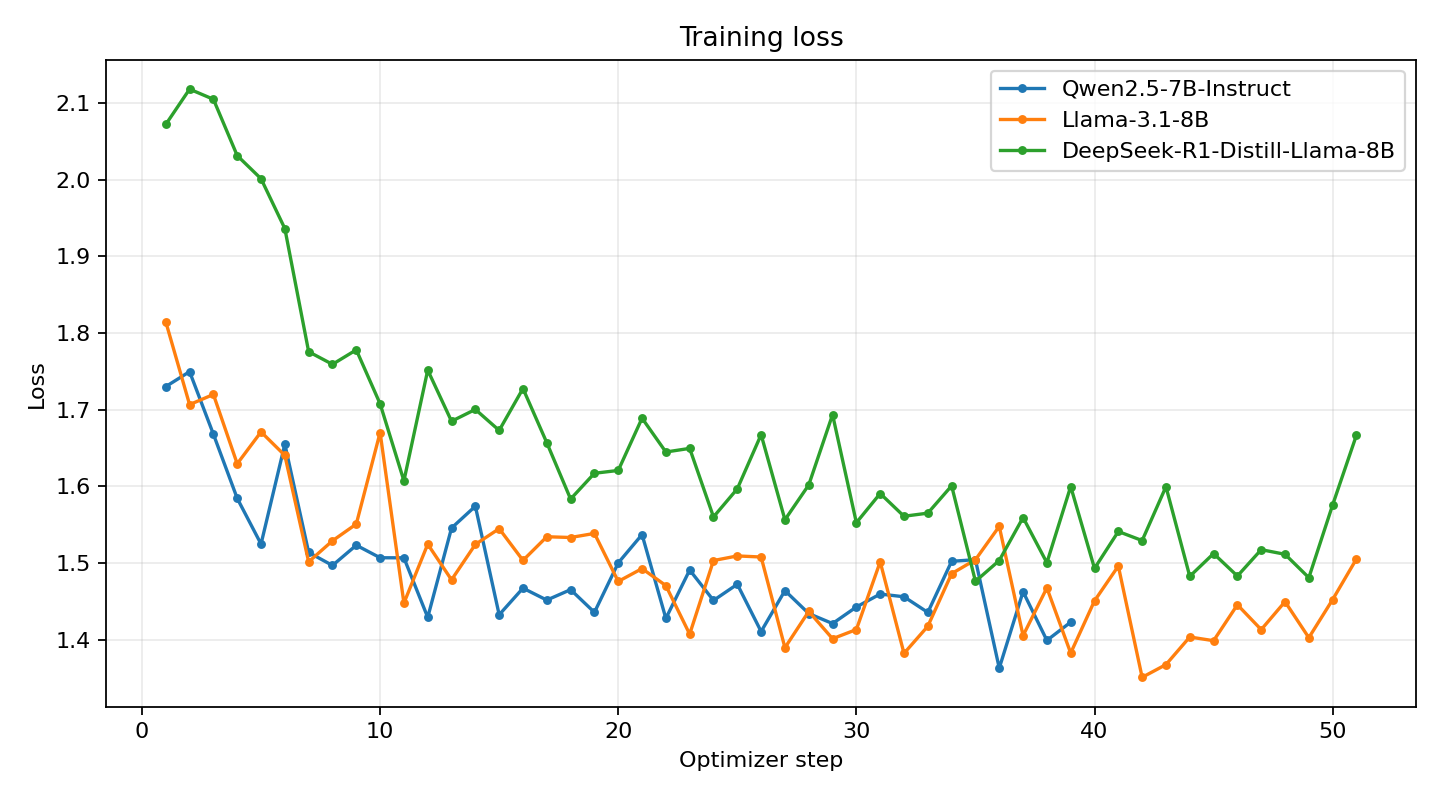


 model_accuracy.png


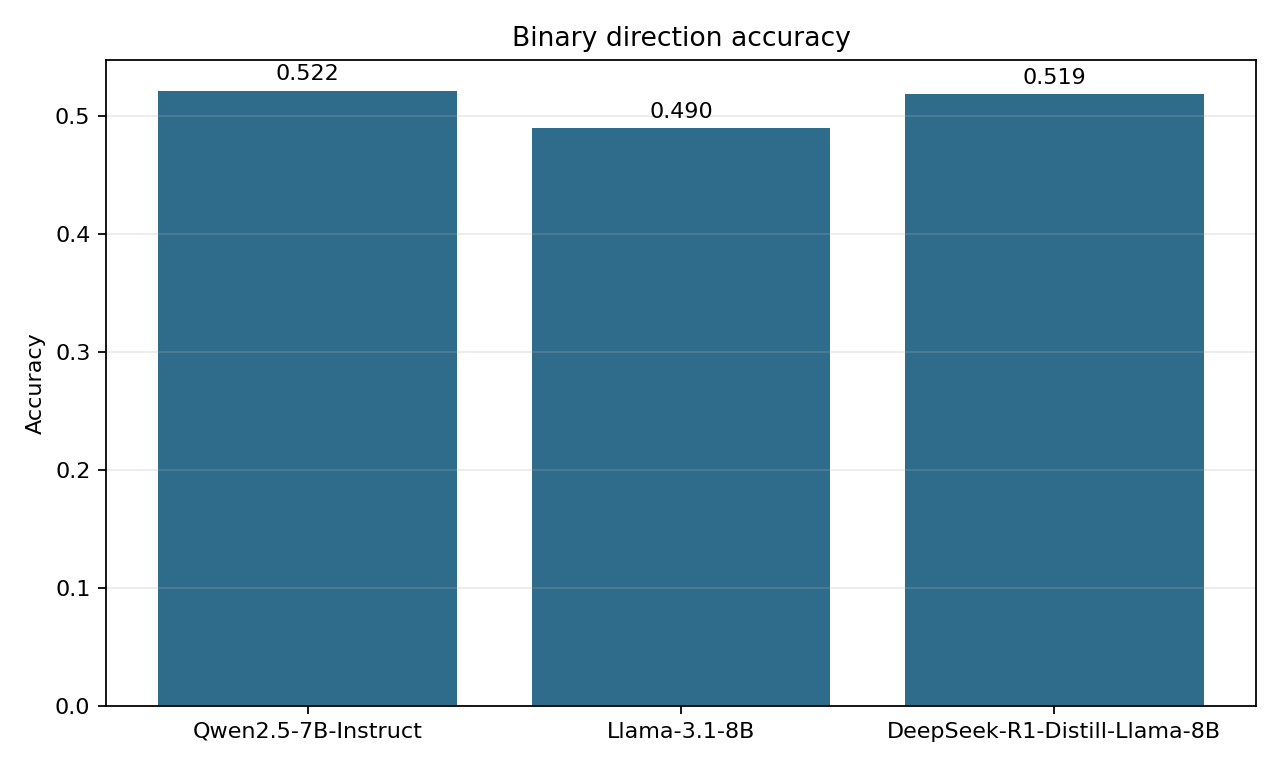


 mse.png


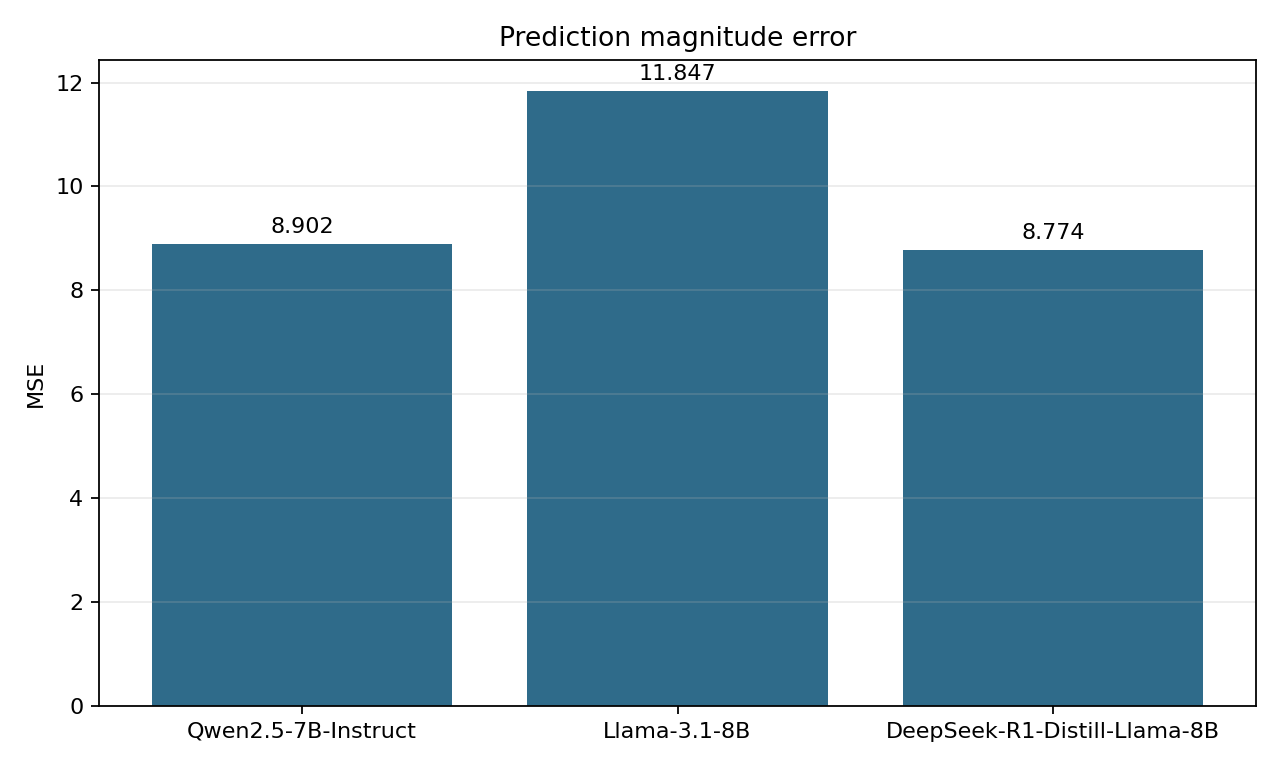


 rouge.png


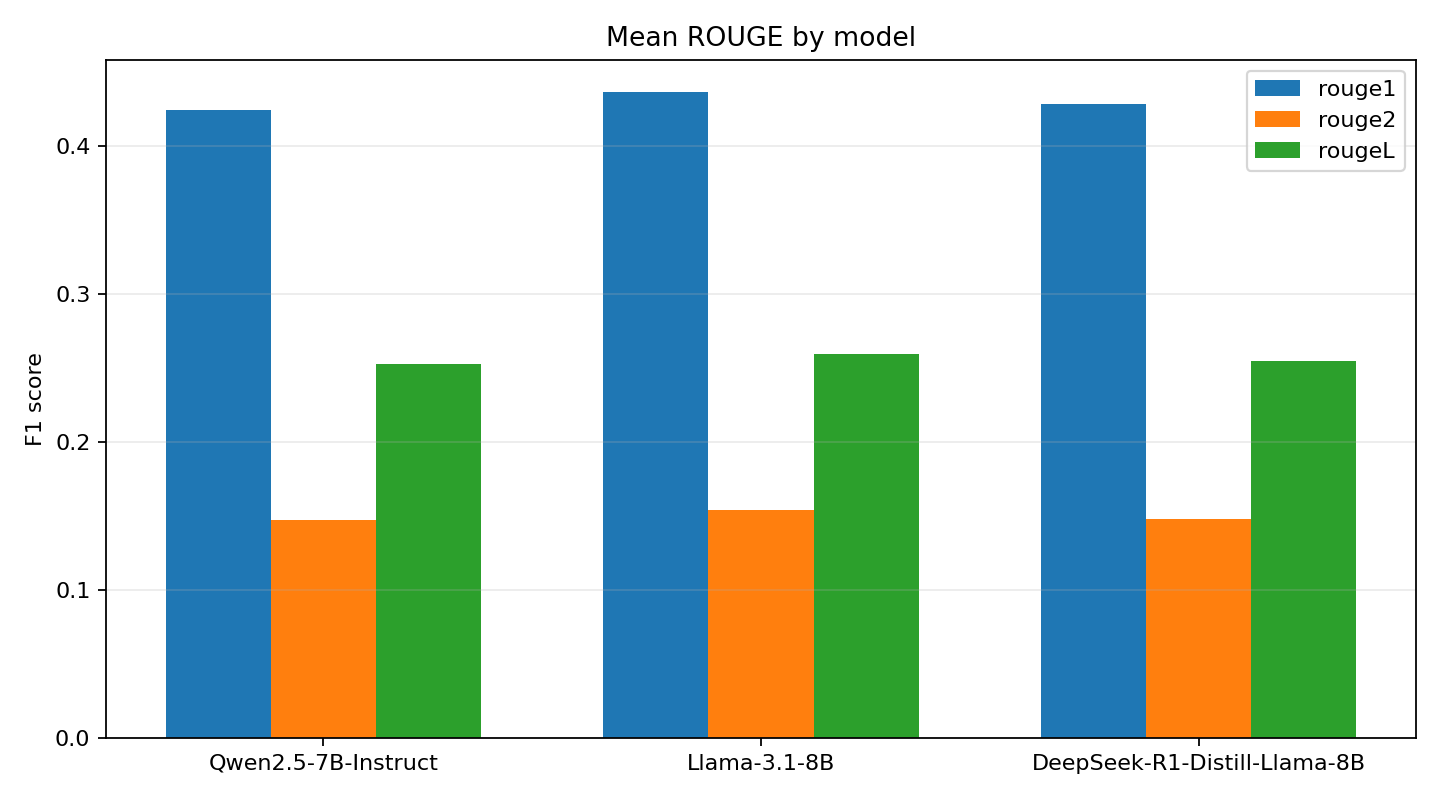


 inference_time.png


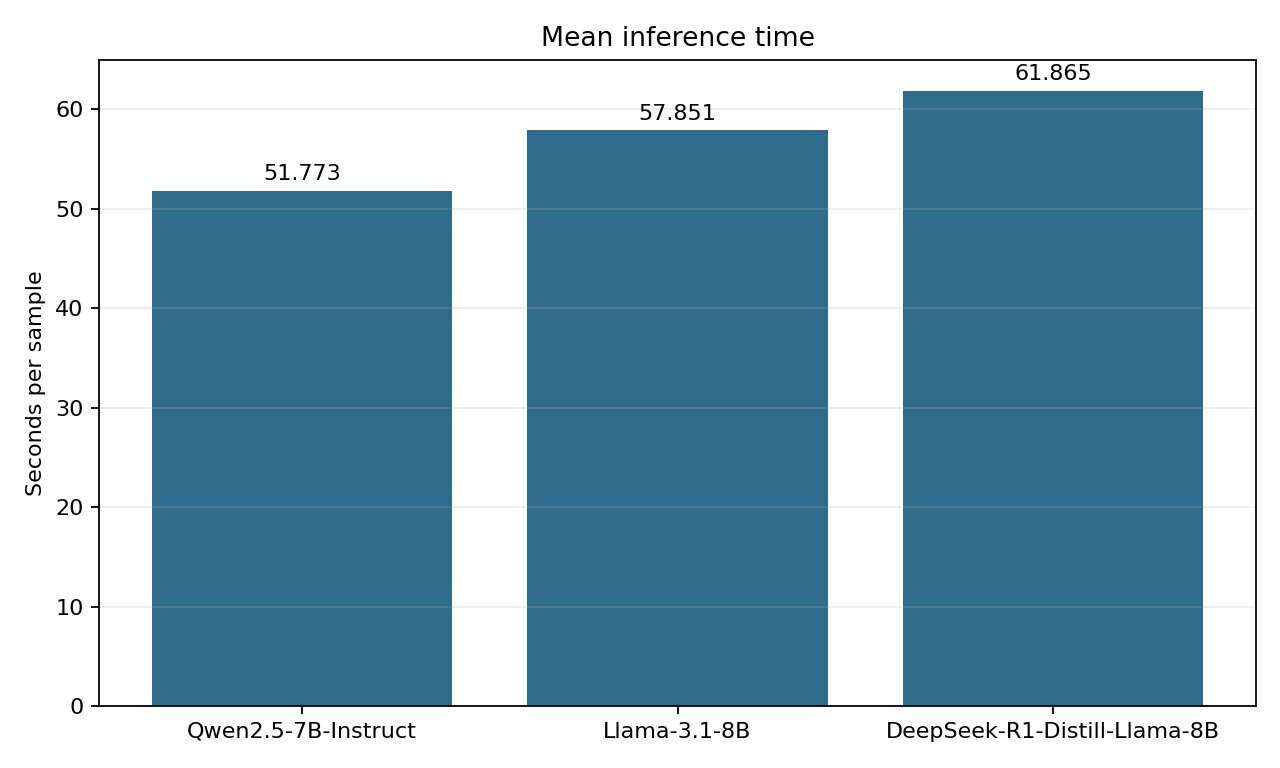

In [52]:
from IPython.display import display, Image
from pathlib import Path

figures_dir = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/figures"
)

for filename in [
    "training_loss.png",
    "model_accuracy.png",
    "mse.png",
    "rouge.png",
    "inference_time.png",
]:
    print("\n", filename)
    display(Image(filename=str(figures_dir / filename)))

In [54]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!rm -rf /content/qwen_r16_smoke_test

!python train_lora.py \
  --model-name Qwen/Qwen2.5-7B-Instruct \
  --model-family qwen2.5 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/qwen_r16_smoke_test \
  --run-name qwen_r16_smoke_test \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 1 \
  --learning-rate 5e-5 \
  --weight-decay 0.01 \
  --num-epochs 1 \
  --max-steps 1 \
  --warmup-ratio 0.03 \
  --scheduler constant \
  --lora-r 16 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision auto \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --logging-steps 1 \
  --eval-strategy no \
  --save-strategy no \
  --report-to none \
  --num-workers 0 \
  --max-train-samples 2 \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
config.json: 100% 663/663 [00:00<00:00, 2.86MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 3.05MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 69.0MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 67.3MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 108MB/s]
Tokenizing train: 100% 2/2 [00:00<00:00, 52.27 examples/s]
Filtering long train examples: 100% 2/2 [00:00<00:00, 263.51 examples/s]
model.safetensors.index.json: 100% 27.8k/27.8k [00:00<00:00, 75.9MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0% 0/4 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/7.81G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/15.2G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/15.2G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 67.1M/15.2G [00:01<05:01, 50.4MB/s]
Reconstructing (incomplete total...):  1

In [55]:
from pathlib import Path
import json

output = Path("/content/qwen_r16_smoke_test")
metrics = json.loads((output / "train_results.json").read_text())
config = json.loads((output / "run_config.json").read_text())

required = {
    "adapter_config.json",
    "adapter_manifest.json",
    "adapter_model.safetensors",
    "run_config.json",
    "trainer_state.json",
    "train_results.json",
}

names = {item.name for item in output.iterdir()}
missing = required - names

forbidden = [
    name for name in names
    if name == "model.safetensors"
    or name == "pytorch_model.bin"
    or name.startswith("model-")
    or name.startswith("pytorch_model-")
]

print("Missing required files:", sorted(missing))
print("Forbidden full-model files:", sorted(forbidden))
print("LoRA rank:", config["lora_r"])
print("Trainable parameters:", config["trainable_parameters"])
print(
    "Adapter size MiB:",
    round((output / "adapter_model.safetensors").stat().st_size / 1024**2, 2),
)
print("Train loss:", metrics["train_loss"])
print("Runtime:", metrics["train_runtime"])
print("Peak allocated GiB:", metrics["gpu_peak_allocated_gib"])
print("Peak reserved GiB:", metrics["gpu_peak_reserved_gib"])

assert not missing
assert not forbidden
assert config["lora_r"] == 16

print("Qwen rank-16 smoke test passed.")

Missing required files: []
Forbidden full-model files: []
LoRA rank: 16
Trainable parameters: 40370176
Adapter size MiB: 154.05
Train loss: 1.713120698928833
Runtime: 36.721
Peak allocated GiB: 11.69161605834961
Peak reserved GiB: 12.681640625
Qwen rank-16 smoke test passed.


In [56]:
from pathlib import Path
import os

assert os.path.ismount("/content/drive"), "Google Drive is not mounted."

output_dir = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/qwen_r16"
)
output_dir.parent.mkdir(parents=True, exist_ok=True)

if output_dir.exists() and any(output_dir.iterdir()):
    print("STOP: Qwen rank-16 output already contains:")
    for item in sorted(output_dir.iterdir()):
        print(item.name)
else:
    print("Qwen rank-16 output directory is ready.")

Qwen rank-16 output directory is ready.


In [58]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python train_lora.py \
  --model-name Qwen/Qwen2.5-7B-Instruct \
  --model-family qwen2.5 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_r16 \
  --run-name qwen_r16 \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 16 \
  --learning-rate 5e-5 \
  --weight-decay 0.01 \
  --num-epochs 1 \
  --warmup-ratio 0.03 \
  --scheduler constant \
  --lora-r 16 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision auto \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --logging-steps 1 \
  --eval-strategy no \
  --save-strategy steps \
  --save-steps 5 \
  --save-total-limit 2 \
  --report-to tensorboard \
  --num-workers 2 \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Tokenizing train: 100% 1230/1230 [00:09<00:00, 132.56 examples/s]
Filtering long train examples: 100% 1230/1230 [00:03<00:00, 408.64 examples/s]
Loading weights: 100% 339/339 [01:01<00:00,  5.55it/s]
trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273
I0000 00:00:1791531383.140403  236665 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791531389.907242  236665 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated token

In [60]:
from pathlib import Path

checkpoint = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/qwen_r16/checkpoint-10"
)

print("Checkpoint exists:", checkpoint.is_dir())

if checkpoint.is_dir():
    for item in sorted(checkpoint.iterdir()):
        print(
            item.name,
            round(item.stat().st_size / 1024**2, 2),
            "MiB",
        )

required = {
    "adapter_config.json",
    "adapter_model.safetensors",
    "trainer_state.json",
    "optimizer.pt",
    "scheduler.pt",
}

missing = required - {
    item.name for item in checkpoint.iterdir()
} if checkpoint.is_dir() else required

print("Missing checkpoint files:", sorted(missing))

assert checkpoint.is_dir()
assert not missing

print("Checkpoint 10 is complete.")

Checkpoint exists: True
README.md 0.0 MiB
adapter_config.json 0.0 MiB
adapter_model.safetensors 154.05 MiB
chat_template.jinja 0.0 MiB
optimizer.pt 78.65 MiB
rng_state.pth 0.01 MiB
scheduler.pt 0.0 MiB
tokenizer.json 10.89 MiB
tokenizer_config.json 0.0 MiB
trainer_state.json 0.01 MiB
training_args.bin 0.01 MiB
Missing checkpoint files: []
Checkpoint 10 is complete.


In [61]:
!nvidia-smi

Fri Oct  9 10:19:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [62]:
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

print(
    "PYTORCH_CUDA_ALLOC_CONF:",
    os.environ["PYTORCH_CUDA_ALLOC_CONF"],
)

PYTORCH_CUDA_ALLOC_CONF: expandable_segments:True


In [63]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True \
python train_lora.py \
  --model-name Qwen/Qwen2.5-7B-Instruct \
  --model-family qwen2.5 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --cache-dir /content/hf-model-cache \
  --output-dir /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_r16 \
  --run-name qwen_r16 \
  --resume-from-checkpoint /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_r16/checkpoint-10 \
  --max-length 2048 \
  --batch-size 1 \
  --gradient-accumulation-steps 16 \
  --learning-rate 5e-5 \
  --weight-decay 0.01 \
  --num-epochs 1 \
  --warmup-ratio 0.03 \
  --scheduler constant \
  --lora-r 16 \
  --lora-alpha 16 \
  --lora-dropout 0.1 \
  --quantization 4bit \
  --precision auto \
  --gradient-checkpointing \
  --optim paged_adamw_8bit \
  --logging-steps 1 \
  --eval-strategy no \
  --save-strategy steps \
  --save-steps 5 \
  --save-total-limit 2 \
  --report-to tensorboard \
  --num-workers 2 \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Tokenizing train: 100% 1230/1230 [00:07<00:00, 157.24 examples/s]
Filtering long train examples: 100% 1230/1230 [00:04<00:00, 289.34 examples/s]
Loading weights: 100% 339/339 [01:01<00:00,  5.51it/s]
trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273
I0000 00:00:1791541347.658540  278209 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791541352.997881  278209 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated token

In [64]:
from pathlib import Path
import json

output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/qwen_r16"
)

required = {
    "adapter_config.json",
    "adapter_manifest.json",
    "adapter_model.safetensors",
    "run_config.json",
    "trainer_state.json",
    "train_results.json",
}

names = {item.name for item in output.iterdir()}
missing = required - names

forbidden = [
    name for name in names
    if name == "model.safetensors"
    or name == "pytorch_model.bin"
    or name.startswith("model-")
    or name.startswith("pytorch_model-")
]

config = json.loads((output / "run_config.json").read_text())
metrics = json.loads((output / "train_results.json").read_text())

print("Missing required files:", sorted(missing))
print("Forbidden full-model files:", sorted(forbidden))
print("LoRA rank:", config["lora_r"])
print("Trainable parameters:", config["trainable_parameters"])
print(
    "Adapter size MiB:",
    round((output / "adapter_model.safetensors").stat().st_size / 1024**2, 2),
)
print("Train loss:", metrics["train_loss"])
print("Train runtime:", metrics["train_runtime"])
print("Peak allocated GiB:", metrics["gpu_peak_allocated_gib"])
print("Peak reserved GiB:", metrics["gpu_peak_reserved_gib"])

assert not missing
assert not forbidden
assert config["lora_r"] == 16
assert config["trainable_parameters"] == 40370176

print("Complete Qwen rank-16 training passed.")

Missing required files: []
Forbidden full-model files: []
LoRA rank: 16
Trainable parameters: 40370176
Adapter size MiB: 154.05
Train loss: 1.086365012022165
Train runtime: 19193.7015
Peak allocated GiB: 12.884036540985107
Peak reserved GiB: 14.375
Complete Qwen rank-16 training passed.


In [18]:
from pathlib import Path

adapter = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "finetuned_models/qwen_r16/adapter_model.safetensors"
)

print("Rank-16 adapter exists:", adapter.is_file())
print("Adapter size MiB:", round(adapter.stat().st_size / 1024**2, 2))

assert adapter.is_file()

Rank-16 adapter exists: True
Adapter size MiB: 154.05


In [19]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/evaluate.py \
  --base-model Qwen/Qwen2.5-7B-Instruct \
  --adapter-path /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_r16 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --output-path /content/qwen_r16_eval_smoke.jsonl \
  --summary-path /content/qwen_r16_eval_smoke.summary.json \
  --cache-dir /content/hf-model-cache \
  --max-samples 2 \
  --max-input-length 8192 \
  --max-new-tokens 512 \
  --quantization 4bit \
  --precision auto \
  --seed 42 \
  --overwrite

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Generating train split: 100% 1230/1230 [00:00<00:00, 28290.78 examples/s]
Generating test split: 100% 300/300 [00:00<00:00, 34499.25 examples/s]
config.json: 100% 663/663 [00:00<00:00, 3.42MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 10.6MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 39.2MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 37.6MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 87.5MB/s]
model.safetensors.index.json: 100% 27.8k/27.8k [00:00<00:00, 48.8MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0% 0/4 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/3.86G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/7.42G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/15.2G [00:00<?, ?B/s]
Reconstructing (incomplete total...):  27% 4.14G/15.2G [00:53<05:01, 36.8MB/s, 50.5MB/s  ]
Reconstructing

In [20]:
import json
from pathlib import Path

summary = json.loads(
    Path("/content/qwen_r16_eval_smoke.summary.json").read_text()
)

fields = [
    "total_test_samples",
    "selected_test_samples",
    "completed_samples",
    "generation_success_count",
    "generation_error_count",
    "parsable_samples",
    "parsing_success_rate",
    "parse_failure_reasons",
    "average_inference_seconds",
    "complete",
]

for field in fields:
    print(f"{field}: {summary.get(field)}")

total_test_samples: 300
selected_test_samples: 2
completed_samples: 2
generation_success_count: 2
generation_error_count: 0
parsable_samples: 2
parsing_success_rate: 1.0
parse_failure_reasons: {}
average_inference_seconds: 50.75236433499998
complete: True


In [22]:
import json
from pathlib import Path

records = [
    json.loads(line)
    for line in Path("/content/qwen_r16_eval_smoke.jsonl").read_text().splitlines()
    if line.strip()
]

for record in records:
    print("Sample:", record["sample_index"])
    print("Symbol:", record["symbol"])
    print("Reference label:", record["label"])
    print("Prompt tokens:", record["prompt_token_count"])
    print("Generated tokens:", record["generated_token_count"])
    print("Inference seconds:", round(record["inference_seconds"], 2))
    print("Parseable:", record["parseable"])
    print("Failure reason:", record["parse_failure_reason"])
    print("Error:", record["error"])
    print("\nGenerated answer:\n")
    print(record["generated_answer"])

Sample: 0
Symbol: AXP
Reference label: up by 2-3%
Prompt tokens: 1592
Generated tokens: 350
Inference seconds: 53.56
Parseable: True
Failure reason: None
Error: None

Generated answer:

[Positive Developments]:
1. American Express Co. has been performing well in the market, with its stock price increasing from 211.81 to 213.90 over the past few weeks.
2. The company's reputation as a well-known and well-established company with a history of generating consistent profits makes it a reliable investment option.
3. The company's financials show a healthy gross margin of 0.6334, indicating strong profitability.
4. The company's long-term debt to total asset ratio is relatively low at 0.1833, suggesting a manageable level of debt.

[Potential Concerns]:
1. Despite the overall positive performance, American Express Co.'s stock has underperformed compared to its competitors, which could indicate underlying issues.
2. The company's total debt to equity ratio is high at 6.355, which could be a c

In [24]:
from pathlib import Path
import shutil

smoke_output = Path("/content/qwen_r16_eval_smoke.jsonl")
full_output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_r16_outputs.jsonl"
)

assert smoke_output.is_file()
assert not full_output.exists()

shutil.copy2(smoke_output, full_output)

print("Initial rank-16 records:", sum(
    1 for line in full_output.open() if line.strip()
))

Initial rank-16 records: 2


In [25]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/evaluate.py \
  --base-model Qwen/Qwen2.5-7B-Instruct \
  --adapter-path /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_r16 \
  --dataset FinGPT/fingpt-forecaster-dow30-202305-202405 \
  --output-path /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_r16_outputs.jsonl \
  --summary-path /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_r16_outputs.summary.json \
  --cache-dir /content/hf-model-cache \
  --max-input-length 8192 \
  --max-new-tokens 512 \
  --quantization 4bit \
  --precision auto \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Loading weights: 100% 339/339 [01:01<00:00,  5.55it/s]
Evaluating 298 pending samples; appending to /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_r16_outputs.jsonl
[3/300] sample=2 parseable=True error=False
[4/300] sample=3 parseable=True error=False
[5/300] sample=4 parseable=True error=False
[6/300] sample=5 parseable=True error=False
[7/300] sample=6 parseable=True error=False
[8/300] sample=7 parseable=True error=False
[9/300] sample=8 parseable=True error=False
[10/300] sample=9 parseable=True error=False
[11/300] sample=10 parseable=True error=False
[12/300] sample=11 parseable=True error=False
[13/300] sample=12 parseable=True error=False
[14/300] sample=13 parseable=True error=False
[15/300] sample=14 parseable=True error=False
[16/300] sample=15 parseable=True error=False
[17/300] sample=16 parseable=True error=False
[18/300] sample=17 parseable=True error=False
[19/300] sample=18 parseable=True error=Fals

In [26]:
import json
from pathlib import Path

output = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_r16_outputs.jsonl"
)
summary_path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_r16_outputs.summary.json"
)

records = [
    json.loads(line)
    for line in output.read_text().splitlines()
    if line.strip()
]
summary = json.loads(summary_path.read_text())

print("JSONL records:", len(records))
print("Unique indices:", len({
    record["sample_index"] for record in records
}))
print("Completed:", summary["completed_samples"])
print("Successful:", summary["generation_success_count"])
print("Errors:", summary["generation_error_count"])
print("Parseable:", summary["parsable_samples"])
print("Parsing success rate:", summary["parsing_success_rate"])
print("Parse failure reasons:", summary["parse_failure_reasons"])
print("Average inference seconds:", summary["average_inference_seconds"])
print("Complete:", summary["complete"])

assert len(records) == 300
assert len({record["sample_index"] for record in records}) == 300
assert summary["completed_samples"] == 300
assert summary["complete"] is True

print("Complete Qwen rank-16 evaluation passed.")

JSONL records: 300
Unique indices: 300
Completed: 300
Successful: 300
Errors: 0
Parseable: 300
Parsing success rate: 1.0
Parse failure reasons: {}
Average inference seconds: 52.225436555790004
Complete: True
Complete Qwen rank-16 evaluation passed.


In [27]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/score_outputs.py \
  --input /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_r16_outputs.jsonl \
  --output /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_r16_metrics.json \
  --evaluation-summary /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_r16_outputs.summary.json \
  --run-config /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_r16/run_config.json \
  --trainer-state /content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_r16/trainer_state.json \
  --model-label Qwen2.5-7B-Instruct-r16

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

Binary Accuracy: 0.52  |  Mean Square Error: 9.11

Rouge Score of Positive Developments: {'rouge1': 0.43665372546464476, 'rouge2': 0.16991819564712923, 'rougeL': 0.27562564662295763}

Rouge Score of Potential Concerns: {'rouge1': 0.41103483971780336, 'rouge2': 0.1436986147092275, 'rougeL': 0.2626249043309678}

Rouge Score of Summary Analysis: {'rouge1': 0.4320459428277917, 'rouge2': 0.13062700966267876, 'rougeL': 0.22286508604974087}
{
  "adapter_path": "/content/drive/MyDrive/FinGPT_Assignment1/finetuned_models/qwen_r16",
  "analysis_rouge1": 0.4320459428277917,
  "analysis_rouge2": 0.13062700966267876,
  "analysis_rougeL": 0.22286508604974087,
  "average_inference_seconds": 52.225436555790004,
  "base_model": "Qwen/Qwen2.5-7B-Instruct",
  "binary_accuracy": 0.5185185185185185,
  "completed_samples": 300,
  "concerns_rouge1": 0.41103483971780336,
  "concerns_rouge2": 0.1436986147092275,
  "concerns_rougeL": 0.2626249043309678

In [28]:
import json
from pathlib import Path

metrics_path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_r16_metrics.json"
)

metrics = json.loads(metrics_path.read_text())

fields = [
    "model_label",
    "total_test_samples",
    "completed_samples",
    "generation_success_count",
    "generation_error_count",
    "parsable_samples",
    "valid_count",
    "parsing_success_rate",
    "binary_accuracy",
    "mse",
    "rouge1",
    "rouge2",
    "rougeL",
    "positive_rouge1",
    "positive_rouge2",
    "positive_rougeL",
    "concerns_rouge1",
    "concerns_rouge2",
    "concerns_rougeL",
    "analysis_rouge1",
    "analysis_rouge2",
    "analysis_rougeL",
    "average_inference_seconds",
]

for field in fields:
    print(f"{field}: {metrics.get(field)}")

model_label: Qwen2.5-7B-Instruct-r16
total_test_samples: 300
completed_samples: 300
generation_success_count: 300
generation_error_count: 0
parsable_samples: 300
valid_count: 297
parsing_success_rate: 1.0
binary_accuracy: 0.5185185185185185
mse: 9.11111111111111
rouge1: 0.4265781693367466
rouge2: 0.1480812733396785
rougeL: 0.2537052123345554
positive_rouge1: 0.43665372546464476
positive_rouge2: 0.16991819564712923
positive_rougeL: 0.27562564662295763
concerns_rouge1: 0.41103483971780336
concerns_rouge2: 0.1436986147092275
concerns_rougeL: 0.2626249043309678
analysis_rouge1: 0.4320459428277917
analysis_rouge2: 0.13062700966267876
analysis_rougeL: 0.22286508604974087
average_inference_seconds: 52.225436555790004


In [29]:
assert metrics["completed_samples"] == 300
assert metrics["generation_success_count"] == 300
assert metrics["generation_error_count"] == 0
assert metrics["parsable_samples"] == 300
assert metrics["valid_count"] == 297
assert metrics["binary_accuracy"] is not None
assert metrics["mse"] is not None
assert metrics["rouge1"] is not None
assert metrics["rouge2"] is not None
assert metrics["rougeL"] is not None

run_config = metrics["run_config"]

assert run_config["lora_r"] == 16
assert run_config["trainable_parameters"] == 40370176

print("Qwen rank-16 scoring passed.")

Qwen rank-16 scoring passed.


In [30]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/compare_optimization.py \
  --baseline /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_metrics.json \
  --variant /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_r16_metrics.json \
  --output /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_rank_comparison.csv

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Validated a controlled LoRA-rank experiment and wrote /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_rank_comparison.csv: r=8 versus r=16.


In [31]:
import pandas as pd

comparison_path = (
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_rank_comparison.csv"
)

rank_comparison = pd.read_csv(comparison_path)

display(
    rank_comparison[
        [
            "comparison_row",
            "model_label",
            "lora_rank",
            "trainable_parameter_count",
            "logged_loss_points",
            "initial_training_loss",
            "final_training_loss",
            "minimum_training_loss",
            "training_loss_change",
            "optimizer_steps",
            "valid_count",
            "parsing_success_rate",
            "binary_accuracy",
            "mse",
            "rouge1",
            "rouge2",
            "rougeL",
            "average_inference_seconds",
        ]
    ].round(6)
)

,comparison_row,model_label,lora_rank,trainable_parameter_count,logged_loss_points,initial_training_loss,final_training_loss,minimum_training_loss,training_loss_change,optimizer_steps,valid_count,parsing_success_rate,binary_accuracy,mse,rouge1,rouge2,rougeL,average_inference_seconds
0,baseline,Qwen2.5-7B-Instruct,8.0,20185088.0,39.0,1.730216,1.423170,1.363226,-0.307046,39.0,297.0,1.0,0.521886,8.902357,0.424423,0.147125,0.252685,51.772811
1,variant,Qwen2.5-7B-Instruct-r16,16.0,40370176.0,39.0,1.730216,1.422689,1.362224,-0.307527,39.0,297.0,1.0,0.518519,9.111111,0.426578,0.148081,0.253705,52.225437
2,variant_minus_baseline,Qwen2.5-7B-Instruct-r16 - Qwen2.5-7B-Instruct,8.0,20185088.0,0.0,0.000000,-0.000481,-0.001002,-0.000481,0.0,0.0,0.0,-0.003367,0.208754,0.002155,0.000956,0.001021,0.452626


In [32]:
from pathlib import Path
import pandas as pd

path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_rank_comparison.csv"
)

table = pd.read_csv(path)

assert len(table) == 3
assert table.iloc[0]["comparison_row"] == "baseline"
assert table.iloc[1]["comparison_row"] == "variant"
assert table.iloc[2]["comparison_row"] == "variant_minus_baseline"
assert int(table.iloc[0]["lora_rank"]) == 8
assert int(table.iloc[1]["lora_rank"]) == 16

print("Qwen controlled rank comparison passed.")

Qwen controlled rank comparison passed.


In [33]:
from pathlib import Path
import os

assert os.path.ismount("/content/drive")

hitl_dir = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/hitl"
)
hitl_dir.mkdir(parents=True, exist_ok=True)

review_path = hitl_dir / "hitl_review.csv"

if review_path.exists():
    print("STOP: A HITL review form already exists:")
    print(review_path)
    print("Size:", review_path.stat().st_size)
else:
    print("HITL output path is ready.")

HITL output path is ready.


In [34]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python hitl/create_hitl.py \
  --outputs \
    "Qwen2.5-7B-Instruct=/content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_outputs.jsonl" \
    "Llama-3.1-8B=/content/drive/MyDrive/FinGPT_Assignment1/evaluation/llama_outputs.jsonl" \
    "DeepSeek-R1-Distill-Llama-8B=/content/drive/MyDrive/FinGPT_Assignment1/evaluation/deepseek_outputs.jsonl" \
    "Qwen2.5-7B-Instruct-r16=/content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_r16_outputs.jsonl" \
  --output /content/drive/MyDrive/FinGPT_Assignment1/hitl/hitl_review.csv \
  --samples-per-model 6 \
  --seed 42

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Wrote 24 unrated responses across 4 models to /content/drive/MyDrive/FinGPT_Assignment1/hitl/hitl_review.csv. Selected sample indices: [12, 57, 71, 114, 125, 140]


In [35]:
from pathlib import Path
import shutil

source = Path(
    "/content/FinGPT_Workspace/submissions/"
    "Assignment1_NAME_UNI/hitl/RUBRIC.md"
)
destination = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "hitl/RUBRIC.md"
)

assert source.is_file()
shutil.copy2(source, destination)

print("Rubric copied:", destination)

Rubric copied: /content/drive/MyDrive/FinGPT_Assignment1/hitl/RUBRIC.md


In [36]:
import csv
from collections import Counter
from pathlib import Path

review_path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "hitl/hitl_review.csv"
)

with review_path.open(newline="") as handle:
    rows = list(csv.DictReader(handle))

rating_columns = [
    "positive_development_quality",
    "concern_risk_quality",
    "financial_reasoning_quality",
    "prediction_justification",
    "factual_grounding",
    "clarity_professionalism",
]

models = Counter(row["model"] for row in rows)
indices = sorted({int(row["sample_index"]) for row in rows})

print("Total rows:", len(rows))
print("Rows per model:", dict(models))
print("Selected sample indices:", indices)
print(
    "All rating fields blank:",
    all(
        not row[column].strip()
        for row in rows
        for column in rating_columns
    ),
)
print(
    "All binary fields blank:",
    all(
        not row[column].strip()
        for row in rows
        for column in [
            "formatting_compliance",
            "hallucination_observed",
        ]
    ),
)

assert len(rows) == 24
assert set(models.values()) == {6}
assert len(indices) == 6
assert all(
    not row[column].strip()
    for row in rows
    for column in rating_columns
)
assert all(
    not row[column].strip()
    for row in rows
    for column in [
        "formatting_compliance",
        "hallucination_observed",
    ]
)

print("HITL review form validation passed.")

Total rows: 24
Rows per model: {'Qwen2.5-7B-Instruct-r16': 6, 'DeepSeek-R1-Distill-Llama-8B': 6, 'Qwen2.5-7B-Instruct': 6, 'Llama-3.1-8B': 6}
Selected sample indices: [12, 57, 71, 114, 125, 140]
All rating fields blank: True
All binary fields blank: True
HITL review form validation passed.


In [37]:
import pandas as pd

review = pd.read_csv(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "hitl/hitl_review.csv"
)

display(
    review[
        [
            "review_id",
            "model",
            "sample_index",
            "symbol",
            "period",
            "label",
        ]
    ]
)

,review_id,model,sample_index,symbol,period,label
0,HITL-001,Qwen2.5-7B-Instruct-r16,125,JNJ,2024-03-31 to 2024-04-07,down by 3-4%
1,HITL-002,DeepSeek-R1-Distill-Llama-8B,114,INTC,2024-03-24 to 2024-03-31,up by 3-4%
2,HITL-003,DeepSeek-R1-Distill-Llama-8B,71,GS,2024-03-03 to 2024-03-10,down by 0-1%
3,HITL-004,Qwen2.5-7B-Instruct-r16,57,CSCO,2024-04-14 to 2024-04-21,down by 0-1%
4,HITL-005,Qwen2.5-7B-Instruct,57,CSCO,2024-04-14 to 2024-04-21,down by 0-1%
5,HITL-006,DeepSeek-R1-Distill-Llama-8B,57,CSCO,2024-04-14 to 2024-04-21,down by 0-1%
6,HITL-007,Llama-3.1-8B,57,CSCO,2024-04-14 to 2024-04-21,down by 0-1%
7,HITL-008,Qwen2.5-7B-Instruct,114,INTC,2024-03-24 to 2024-03-31,up by 3-4%
8,HITL-009,Qwen2.5-7B-Instruct-r16,71,GS,2024-03-03 to 2024-03-10,down by 0-1%
9,HITL-010,Qwen2.5-7B-Instruct-r16,114,INTC,2024-03-24 to 2024-03-31,up by 3-4%


In [42]:
%cd /content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI

!python evaluation/compare_optimization.py \
  --baseline /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_metrics.json \
  --variant /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_r16_metrics.json \
  --output /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_rank_optimization.csv

/content/FinGPT_Workspace/submissions/Assignment1_NAME_UNI
Validated a controlled LoRA-rank experiment and wrote /content/drive/MyDrive/FinGPT_Assignment1/evaluation/qwen_rank_optimization.csv: r=8 versus r=16.


In [43]:
from pathlib import Path
import pandas as pd

path = Path(
    "/content/drive/MyDrive/FinGPT_Assignment1/"
    "evaluation/qwen_rank_optimization.csv"
)

print("Exists:", path.is_file())
print("Size:", path.stat().st_size if path.is_file() else None)

if path.is_file():
    display(pd.read_csv(path))

Exists: True
Size: 1223


,comparison_row,model_label,base_model,lora_rank,trainable_parameter_count,logged_loss_points,initial_training_loss,final_training_loss,minimum_training_loss,training_loss_change,...,binary_accuracy,mse,rouge1,rouge2,rougeL,average_inference_seconds,hitl_completed_reviews,hitl_mean_overall_quality,hitl_formatting_compliance_rate,hitl_hallucination_rate
0,baseline,Qwen2.5-7B-Instruct,Qwen/Qwen2.5-7B-Instruct,8.0,20185088.0,39.0,1.730216,1.423170,1.363226,-0.307046,...,0.521886,8.902357,0.424423,0.147125,0.252685,51.772811,NaN,NaN,NaN,NaN
1,variant,Qwen2.5-7B-Instruct-r16,Qwen/Qwen2.5-7B-Instruct,16.0,40370176.0,39.0,1.730216,1.422689,1.362224,-0.307527,...,0.518519,9.111111,0.426578,0.148081,0.253705,52.225437,NaN,NaN,NaN,NaN
2,variant_minus_baseline,Qwen2.5-7B-Instruct-r16 - Qwen2.5-7B-Instruct,Qwen/Qwen2.5-7B-Instruct,8.0,20185088.0,0.0,0.000000,-0.000481,-0.001002,-0.000481,...,-0.003367,0.208754,0.002155,0.000956,0.001021,0.452626,NaN,NaN,NaN,NaN


In [46]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

ROOT = Path("/content/drive/MyDrive/FinGPT_Assignment1")
ZIP_PATH = ROOT / "report_inputs.zip"

files_to_include = []

# Evaluation outputs, metrics, and comparisons
evaluation_dir = ROOT / "evaluation"
if evaluation_dir.exists():
    files_to_include.extend(
        path for path in evaluation_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in {".json", ".jsonl", ".csv"}
    )

# Figures
figures_dir = ROOT / "figures"
if figures_dir.exists():
    files_to_include.extend(
        path for path in figures_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in {".png", ".pdf", ".svg"}
    )

# Environment information
report_inputs_dir = ROOT / "report_inputs"
if report_inputs_dir.exists():
    files_to_include.extend(
        path for path in report_inputs_dir.rglob("*")
        if path.is_file()
    )

# Small training metadata only—no adapter weights
metadata_names = {
    "run_config.json",
    "trainer_state.json",
    "train_results.json",
    "all_results.json",
    "adapter_manifest.json",
    "adapter_config.json",
}

models_dir = ROOT / "finetuned_models"
if models_dir.exists():
    files_to_include.extend(
        path for path in models_dir.rglob("*")
        if path.is_file() and path.name in metadata_names
    )

files_to_include = sorted(set(files_to_include))

with ZipFile(ZIP_PATH, "w", ZIP_DEFLATED) as archive:
    for path in files_to_include:
        archive.write(path, path.relative_to(ROOT))

print("Created:", ZIP_PATH)
print("Included files:", len(files_to_include))
print("Size MiB:", round(ZIP_PATH.stat().st_size / 1024**2, 2))

Created: /content/drive/MyDrive/FinGPT_Assignment1/report_inputs.zip
Included files: 62
Size MiB: 2.72
